## Analyzing Employer Activity + Zero-Application Job Examples + KPIs
This notebook covers an analysis on Employer Activity and investigates jobs with zero application in BU CCD Handshake employer engagement data (Spring 2020–Summer 2025).

**Contributors: Tessa Thomas, Shaotai Hu (extension + documentation), Sviat Shevchenko (extension (rest of KPIs, deduplications of EAY and JAY, answer questions outside of KPIs scope per notion milestone 2 tasks)**

Last Updated: 3/24/2026

Documentation link https://docs.google.com/document/d/1Bb41HlLYCEw7ClFDz93oFS0ctIXD8MMtMaOlmVGC6xk/edit?usp=sharing

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# ---- File locations ----
# Update DATA_DIR to wherever your CSVs live.
DATA_DIR = ""

#Load in cleaned csv
ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))

# Preview the data
ep_joined.head(5)

/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_63925/558514923.py:14: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))


,name,employer_id,employer_type,employer_creation_date,email,website,employer_size_min,employer_size_max,events_name,event_date,...,employers_name,event_medium,student_attendees_count,employer_name,min_salary,max_salary,job_creation_date,jobs_title,jobs_id,applications_count
0,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",20.0,23.0,2025-02-06,environmental technician,9660425.0,0.0
1,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",0.0,0.0,2024-01-04,entry-level ecologist,8546132.0,0.0
2,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",16.0,16.0,2024-05-08,cultural resource intern,8959118.0,1.0
3,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",0.0,0.0,2023-11-02,environmental technician,8397637.0,0.0
4,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",45000.0,50000.0,2023-10-30,architectural historian,8387960.0,0.0


## Finding Zero-Application Job Examples
This analysis includes August 2025 data

In [2]:
# Make sure job_creation_date is datetime
ep_joined['job_creation_date'] = pd.to_datetime(ep_joined['job_creation_date'], errors='coerce')

# Filter zero-application jobs from large employers in Aug 2025
zero_app_2025 = ep_joined[
    (ep_joined['applications_count'] == 0) &
    ((ep_joined['employer_size_min'] >= 250) | (ep_joined['employer_size_min'].isna())) &
    (ep_joined['job_creation_date'].dt.year == 2025) &
    (ep_joined['job_creation_date'].dt.month == 8) &
    (ep_joined['events_name'].isna())
].drop_duplicates(subset='jobs_id')

# Take a small sample and display key columns
sample_jobs_2025 = zero_app_2025[['jobs_id','jobs_title','employer_name','applications_count','job_creation_date']].head(15)
sample_jobs_2025

,jobs_id,jobs_title,employer_name,applications_count,job_creation_date
26,10110420.0,"assurance intern (las vegas, nv)",eide bailly llp,0.0,2025-08-04
30,10110612.0,"assurance intern (reno, ut)",eide bailly llp,0.0,2025-08-04
32,10110461.0,"entry level tax associate (las vegas, nv)",eide bailly llp,0.0,2025-08-04
51,10110703.0,tax intern (utah),eide bailly llp,0.0,2025-08-04
53,10159741.0,entry level associate (assurance or tax),eide bailly llp,0.0,2025-08-18
54,10159737.0,accounting intern (assurance or tax),eide bailly llp,0.0,2025-08-18
56,10184381.0,tax controversy and procedure intern (fall 2025),eide bailly llp,0.0,2025-08-21
66,10159729.0,accounting intern (assurance or tax),eide bailly llp,0.0,2025-08-18
85,10110382.0,"tax intern (billings, mt)",eide bailly llp,0.0,2025-08-04
86,10113561.0,tax controversy and procedure intern (fall 2025),eide bailly llp,0.0,2025-08-05


Total unique jobs: 562,602
Jobs with 0 applications: 420,690 (74.8%)
Jobs with null applications: 0 (should be 0 per data spec)



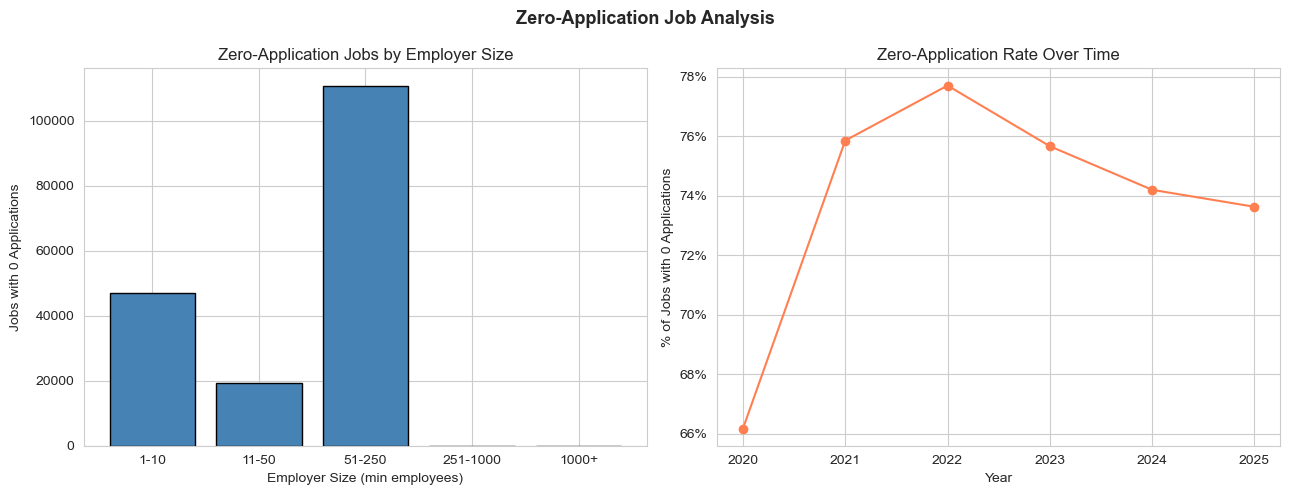


Key finding: 74.8% of all job postings received zero applications.
Per data spec: 0 = true zero demand or off-platform redirect counted as application.
Possible drivers: low keyword visibility, competitive posting month, employer brand recognition,
or job posted but filled via other channels before students applied on Handshake.


In [3]:
# Zero application job short analysis
jobs_unique = ep_joined.dropna(subset=['jobs_id'])\
    .drop_duplicates(subset=['jobs_id']).copy()

total_jobs = len(jobs_unique)
zero_app_jobs = jobs_unique[jobs_unique['applications_count'] == 0].copy()
null_app_jobs = jobs_unique[jobs_unique['applications_count'].isna()]

print(f"Total unique jobs: {total_jobs:,}")
print(f"Jobs with 0 applications: {len(zero_app_jobs):,} ({100*len(zero_app_jobs)/total_jobs:.1f}%)")
print(f"Jobs with null applications: {len(null_app_jobs):,} (should be 0 per data spec)")
print()

# Zero app jobs by employer size
zero_app_jobs['size_group'] = pd.cut(
    zero_app_jobs['employer_size_min'].fillna(0),
    bins=[0, 10, 50, 250, 1000, float('inf')],
    labels=['1-10', '11-50', '51-250', '251-1000', '1000+']
)
size_zero = zero_app_jobs['size_group'].value_counts().sort_index()

# Zero app jobs by year
zero_app_jobs['year'] = pd.to_datetime(
    zero_app_jobs['job_creation_date'], errors='coerce'
).dt.year
zero_by_year = zero_app_jobs.groupby('year').size()
total_by_year = jobs_unique.groupby(
    pd.to_datetime(jobs_unique['job_creation_date'], errors='coerce').dt.year
).size()
zero_pct_by_year = (zero_by_year / total_by_year * 100).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(size_zero.index, size_zero.values, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Employer Size (min employees)')
axes[0].set_ylabel('Jobs with 0 Applications')
axes[0].set_title('Zero-Application Jobs by Employer Size')

axes[1].plot(zero_pct_by_year.index, zero_pct_by_year.values, marker='o', color='coral')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('% of Jobs with 0 Applications')
axes[1].set_title('Zero-Application Rate Over Time')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.suptitle('Zero-Application Job Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nKey finding: {100*len(zero_app_jobs)/total_jobs:.1f}% of all job postings received zero applications.")
print("Per data spec: 0 = true zero demand or off-platform redirect counted as application.")
print("Possible drivers: low keyword visibility, competitive posting month, employer brand recognition,")
print("or job posted but filled via other channels before students applied on Handshake.")

## Analyzing employer activity on Handshake, including job postings and event participation


/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_63925/3994984192.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=jobs_per_month.index, y=jobs_per_month.values, palette="Blues_d")


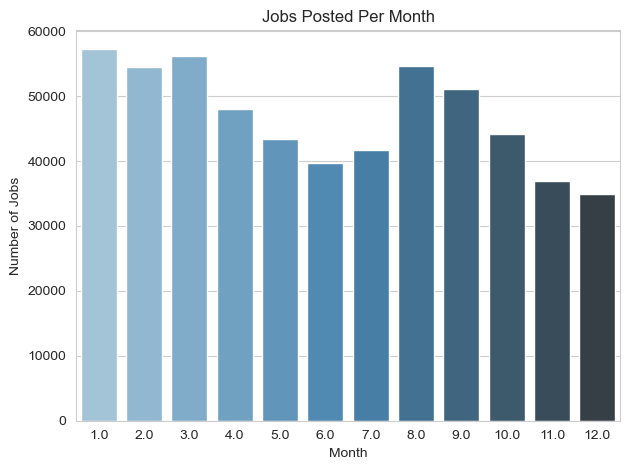

In [4]:
# -----------------------------
# Jobs Posted Per Month (Fixed)
# -----------------------------
ep_joined['job_month'] = ep_joined['job_creation_date'].dt.month
jobs_per_month = ep_joined.groupby('job_month')['jobs_id'].nunique()

sns.barplot(x=jobs_per_month.index, y=jobs_per_month.values, palette="Blues_d")
plt.xlabel("Month")
plt.ylabel("Number of Jobs")
plt.title("Jobs Posted Per Month")
plt.tight_layout()
plt.show()

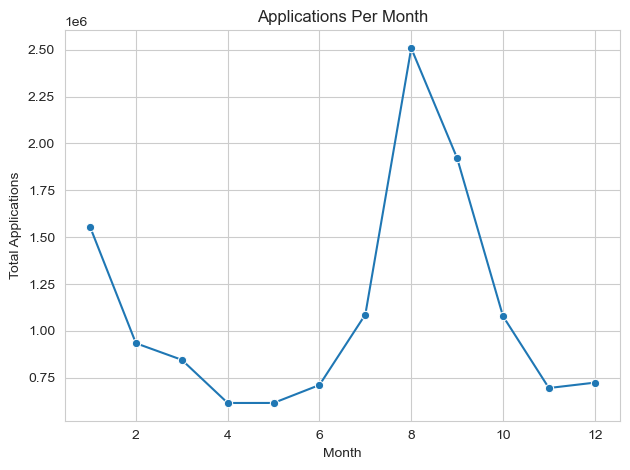

In [5]:
# -----------------------------
# Applications Per Month (New)
# -----------------------------

apps_per_month = ep_joined.groupby('job_month')['applications_count'].sum()

sns.lineplot(x=apps_per_month.index, y=apps_per_month.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Total Applications")
plt.title("Applications Per Month")
plt.tight_layout()
plt.show()


# Details on Definitions Used Below

### Employer Engagement Intensity Score (EEIS): How deeply an employer engages with BU across multiple channels, not just posting jobs.
### Weighted score combination -> EEISe= w1(Job Posts) + w2(Events) + w3(Student Interactions) + w4(Applications)
### Job Application Yield (JAY): How frequently/effectively posted jobs attract student applications. 
### JAY = Applications Count / Jobs Posted    + Salary Signaling Index (SSI) = Avg Salary x JAY, showing whether compensation drives student interest. 
### Event Attendance Yield (EAY): How frequently/effectively hosted events attract student attendees.
### EAY = Student Attendees / Events Hosted
### Define Employer Engagement Breadth (EEB) and Employer Engagement Consistency (EEC) as measures of how active employers are on the handshake platform and a way of segmenting them for visualization, EEB = 1(Posted Jobs) + 1(Hosted Events) and EEC = Active Years / Years Since First Activity.										
### Application Concentration Index (ACI): Whether student interest is spread across postings or concentrated in one job. ACI = (max (Applications per Job)) / Total Applications

## Calculating Job Application Yield

In [6]:
# Aggregate jobs and applications by employer
employer_jobs = ep_joined.groupby('employer_id')['jobs_id'].nunique()

# Deduplicate to one row per employer-job before summing to avoid
# inflation from repeated job rows across multiple event rows in the join
employer_apps = (
    ep_joined
    .dropna(subset=['jobs_id'])
    .drop_duplicates(subset=['employer_id', 'jobs_id'])
    .groupby('employer_id')['applications_count']
    .sum()
)

# Combine into df
employer_inf = pd.DataFrame({
    'total_jobs': employer_jobs,
    'total_applications': employer_apps
})

# Calculate JAY
employer_inf['JAY'] = employer_inf['total_applications'] / employer_inf['total_jobs']

# Add employer names
employer_inf['employer_name'] = ep_joined.groupby('employer_id')['employer_name'].first()

**Note:** Job Application Yield (JAY): How frequently/effectively posted jobs attract student applications.

JAY = Applications Count / Jobs Posted  

In [7]:
# Display top 10 by JAY
top_jay = employer_inf.sort_values('JAY', ascending=False)
top_jay[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10) # <- change number in parantheses to display more

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
27346,delta partners,2,862.0,431.0
1043347,anqora consulting,1,286.0,286.0
1000251,encora therapeutics,1,283.0,283.0
517355,vermilion rock,1,223.0,223.0
974673,fundamental research labs,1,181.0,181.0
98259,computer trust corporation,1,171.0,171.0
999976,global quality partners,1,156.0,156.0
978345,sharpstakes,1,152.0,152.0
1002531,compliers,1,150.0,150.0


In [8]:
# Display bottom 10 by JAY
least_jay = employer_inf.sort_values('JAY', ascending=True)
least_jay[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10)

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
1061634,alumboost,1,0.0,0.0
221927,the school district of university city,1,0.0,0.0
741403,parasol structures inc,1,0.0,0.0
741386,guy nielson company,1,0.0,0.0
741341,"funding opportunities america, llc.",1,0.0,0.0
741290,david n. deutsch & company | theboardadvisor,3,0.0,0.0
741275,"cornell cooperative extension, putnam",1,0.0,0.0
222140,the center for alaskan coastal studies,7,0.0,0.0
222165,new providence board of education,2,0.0,0.0


In [9]:
# Display top 10 specific employers by JAY
target_ids = [14072, 14613, 8530, 14620, 9226, 13661, 39013, 11227, 12397, 15384]

top_jay_specific = employer_inf[employer_inf.index.isin(target_ids)].sort_values('JAY', ascending=False)
top_jay_specific[['employer_name', 'total_jobs', 'total_applications', 'JAY']]

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
14072,goldman sachs,164,6919.0,42.189024
8530,kpmg llp,140,4326.0,30.900000
14620,mckinsey & company,178,4198.0,23.584270
11227,"google, inc.",93,1886.0,20.279570
12397,fidelity investments,165,2787.0,16.890909
13661,morgan stanley,450,5346.0,11.880000
39013,pwc,221,2615.0,11.832579
9226,ey,383,2723.0,7.109661
15384,smbc,267,1823.0,6.827715


In [10]:
employer_inf.sort_values('total_applications', ascending=False)[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10)

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
22003,amazon,795,14015.0,17.628931
18383,jpmorganchase,985,9732.0,9.880203
341398,boston children's hospital,1323,9248.0,6.990174
8750,ibm,985,8688.0,8.820305
53645,boston university,545,8158.0,14.968807
14072,goldman sachs,164,6919.0,42.189024
20014,wayfair,343,5840.0,17.026239
13661,morgan stanley,450,5346.0,11.880000
17372,tesla,926,5113.0,5.521598


In [11]:
#Summary Stats for JAY column
jay_stats = employer_inf['JAY'].describe()
jay_stats

count    31929.000000
mean         2.565738
std          8.780190
min          0.000000
25%          0.000000
50%          0.125000
75%          1.571429
max        431.000000
Name: JAY, dtype: float64

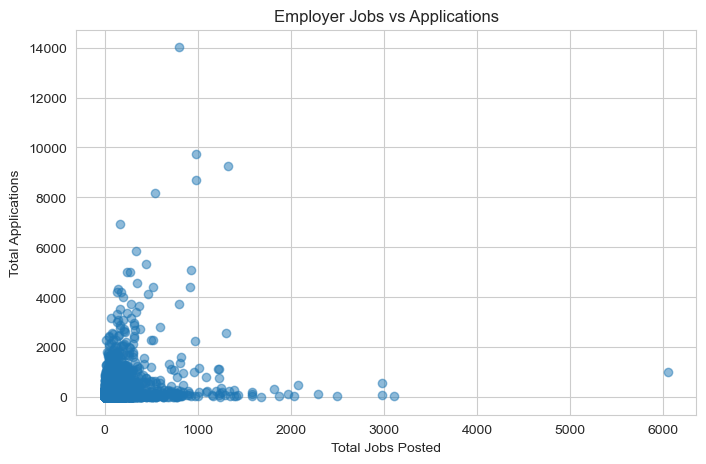

In [12]:
# Scatter plot of Jobs vs Applications
plt.figure(figsize=(8,5))
plt.scatter(employer_inf['total_jobs'], employer_inf['total_applications'], alpha=0.5)
plt.xlabel("Total Jobs Posted")
plt.ylabel("Total Applications")
plt.title("Employer Jobs vs Applications")
plt.show()

## Analyzing Event Participation
Focusing on what employers host events and weighting them based on student attendance

In [13]:
# Filter out invalid events
valid_events = ep_joined['events_name'].notna() & (ep_joined['events_name'].str.strip() != '')

# Count unique events per employer (deduplicated via events_id)
total_events = (
    ep_joined[valid_events]
    .dropna(subset=['events_id'])
    .drop_duplicates(subset=['employer_id', 'events_id'])
    .groupby('employer_id')['events_id']
    .count()
    .rename('total_events')
)

# Total student attendees per employer (deduplicated via events_id)
total_attendees = (
    ep_joined
    .dropna(subset=['events_id'])
    .drop_duplicates(subset=['employer_id', 'events_id'])
    .groupby('employer_id')['student_attendees_count']
    .sum()
    .rename('total_attendees')
)

# Add to employer_inf
if 'employer_name' not in employer_inf.columns:
    employer_inf['employer_name'] = ep_joined.groupby('employer_id')['employer_name'].first()

employer_inf['total_events'] = total_events
employer_inf['total_events'] = employer_inf['total_events'].fillna(0)
employer_inf['total_attendees'] = total_attendees
employer_inf['total_attendees'] = employer_inf['total_attendees'].fillna(0)

# Calculate Event Score
employer_inf['event_score'] = employer_inf['total_events'] + employer_inf['total_attendees']

In [14]:
#Summary Stats for event score column
event_score_stats = employer_inf['event_score'].describe()
event_score_stats

count    56089.000000
mean         1.207349
std         30.173252
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2718.000000
Name: event_score, dtype: float64

In [15]:
# Top 10 employers by Event Score
top_event_employers = employer_inf.sort_values('event_score', ascending=False)
top_event_employers[['employer_name','total_events','total_attendees','event_score']].head(10)

,employer_name,total_events,total_attendees,event_score
employer_id,,,,
9226,ey,314.0,2404.0,2718.0
39013,pwc,173.0,2261.0,2434.0
8594,deloitte,81.0,1890.0,1971.0
14620,mckinsey & company,165.0,1797.0,1962.0
11227,"google, inc.",96.0,1757.0,1853.0
12397,fidelity investments,71.0,1740.0,1811.0
14072,goldman sachs,129.0,1596.0,1725.0
8530,kpmg llp,158.0,1535.0,1693.0
13661,morgan stanley,185.0,1386.0,1571.0


In [16]:
# Bottom 10 employers by Event Score
bot_event_employers = employer_inf.sort_values('event_score', ascending=True)
bot_event_employers[['employer_name','total_events','total_attendees','event_score']].head(10)

,employer_name,total_events,total_attendees,event_score
employer_id,,,,
8406,von maur,0.0,0.0,0.0
578028,"xbiologix, inc",0.0,0.0,0.0
578085,oak knoll school of the holy child,0.0,0.0,0.0
578089,None,0.0,0.0,0.0
578117,None,0.0,0.0,0.0
578186,None,0.0,0.0,0.0
578189,damato chiropractic center,0.0,0.0,0.0
578197,None,0.0,0.0,0.0
578215,kr boston at keller williams,0.0,0.0,0.0


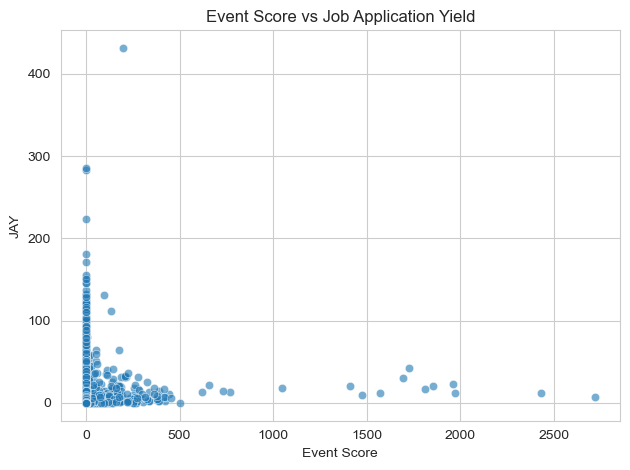

In [17]:
# ----------------------------
# Event Score vs JAY (New)
# ----------------------------

sns.scatterplot( data=employer_inf, x='event_score', y='JAY', alpha=0.6 )
plt.xlabel("Event Score")
plt.ylabel("JAY")
plt.title("Event Score vs Job Application Yield")
plt.tight_layout()
plt.show()

## Analyzing Employer Consistency
Separate Measures for Jobs and Events

In [18]:
# Make sure dates are datetime
ep_joined['job_creation_date'] = pd.to_datetime(ep_joined['job_creation_date'], errors='coerce')
ep_joined['event_date'] = pd.to_datetime(ep_joined['event_date'], errors='coerce')

# Calculate active years per employer for jobs
jobs_years = ep_joined.groupby('employer_id')['job_creation_date'].agg(['min','max'])
jobs_years['active_years_jobs'] = jobs_years['max'].dt.year - jobs_years['min'].dt.year + 1

# Calculate active years per employer for events
events_years = ep_joined.groupby('employer_id')['event_date'].agg(['min','max'])
events_years['active_years_events'] = events_years['max'].dt.year - events_years['min'].dt.year + 1

# Add directly to employer_inf
employer_inf['active_years_jobs'] = employer_inf.index.map(jobs_years['active_years_jobs'])
employer_inf['active_years_events'] = employer_inf.index.map(events_years['active_years_events'])
employer_inf['active_years_jobs'] = employer_inf['active_years_jobs'].fillna(0)
employer_inf['active_years_events'] = employer_inf['active_years_events'].fillna(0)

# Calculate consistency
total_possible_years = ep_joined['job_creation_date'].dt.year.max() - ep_joined['job_creation_date'].dt.year.min() + 1
employer_inf['consistency_jobs'] = employer_inf['active_years_jobs'] / total_possible_years
employer_inf['consistency_events'] = employer_inf['active_years_events'] / total_possible_years

In [19]:
#Summary stats for consistency column
employer_inf['consistency_jobs'].describe()

count    56089.000000
mean         0.227418
std          0.294288
min          0.000000
25%          0.000000
50%          0.166667
75%          0.333333
max          1.000000
Name: consistency_jobs, dtype: float64

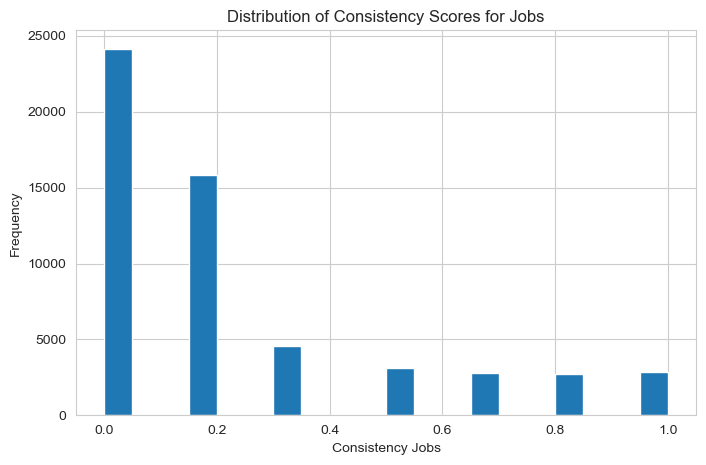

In [20]:
#Visualize Distribution of Consistency Scores for Jobs
plt.figure(figsize=(8,5))
plt.hist(employer_inf['consistency_jobs'], bins=20)
plt.xlabel('Consistency Jobs')
plt.ylabel('Frequency')
plt.title('Distribution of Consistency Scores for Jobs')
plt.show()

In [21]:
# View top 10 consistent employers for jobs
top_consistent_jobs = employer_inf.sort_values('consistency_jobs', ascending=False)
top_consistent_jobs[['employer_name','active_years_jobs','consistency_jobs']].head(10)

,employer_name,active_years_jobs,consistency_jobs
employer_id,,,
174269,y-12 national security complex,6.0,1.0
29767,nelson mullins riley & scarborough llp,6.0,1.0
174992,"western ecosystems technology, inc.",6.0,1.0
29784,neufeld scheck brustin hoffmann & freudenberge...,6.0,1.0
29822,new jersey future,6.0,1.0
175032,easterseals new hampshire,6.0,1.0
446986,truporch homes,6.0,1.0
175106,dhl express,6.0,1.0
175123,intermountain health,6.0,1.0


In [22]:
# View top 10 consistent employers for events
top_consistent_events = employer_inf.sort_values('consistency_events', ascending=False)
top_consistent_events[['employer_name','active_years_events','consistency_events']].head(10)

,employer_name,active_years_events,consistency_events
employer_id,,,
15767,wipfli,6.0,1.0
19110,aramark,6.0,1.0
12709,saga education,6.0,1.0
23924,mayo clinic,6.0,1.0
32606,yale university,6.0,1.0
11551,enterprise mobility,6.0,1.0
18583,burlington stores,6.0,1.0
12910,"fast enterprises, llc",6.0,1.0
21674,dana-farber cancer institute,6.0,1.0


In [23]:
# View top 10 inconsistent employers for jobs
top_inconsistent_jobs = (
    employer_inf[employer_inf['employer_name'].notna()]
    .sort_values('consistency_jobs', ascending=True)
)

top_inconsistent_jobs[['employer_name','active_years_jobs','consistency_jobs']].head(10)

,employer_name,active_years_jobs,consistency_jobs
employer_id,,,
1061634,alumboost,1.0,0.166667
200261,central kentucky ag credit,1.0,0.166667
709985,space craft,1.0,0.166667
200316,black lab sports,1.0,0.166667
200322,bollore logistics,1.0,0.166667
200336,city of seattle parks and recreation department,1.0,0.166667
709976,fashion for all foundation,1.0,0.166667
200419,kongbasileconsulting,1.0,0.166667
709921,"discovery mental health counseling, pllc",1.0,0.166667


In [24]:
# View top 10 inconsistent employers for events
top_inconsistent_events = (
    employer_inf[employer_inf['employer_name'].notna()]
    .sort_values('consistency_events', ascending=True)
)

top_inconsistent_events[['employer_name','active_years_events','consistency_events']].head(10)

,employer_name,active_years_events,consistency_events
employer_id,,,
8406,von maur,0.0,0.0
633724,university of notre dame - oit help desk,0.0,0.0
633699,tbc - the beach club centerville,0.0,0.0
633592,vision solar llc,0.0,0.0
633589,beginning years child development center,0.0,0.0
633544,tropic,0.0,0.0
633532,"s. lichtenberg & co., inc.",0.0,0.0
633470,kured,0.0,0.0
633469,corner co-op nursery school,0.0,0.0


**Note:** Some employer ids were associated with missing employer names and were dropped in the top_inconsistent dfs

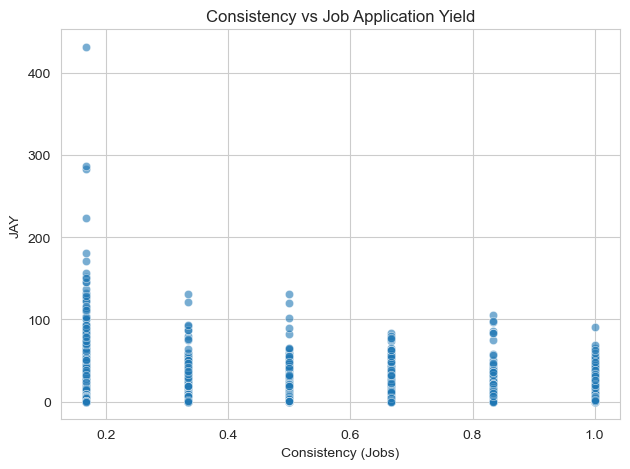

In [25]:
# -----------------------------
# Consistency vs JAY (new)
# -----------------------------

sns.scatterplot( data=employer_inf, x='consistency_jobs', y='JAY', alpha=0.6 )
plt.xlabel("Consistency (Jobs)")
plt.ylabel("JAY")
plt.title("Consistency vs Job Application Yield")
plt.tight_layout()
plt.show()

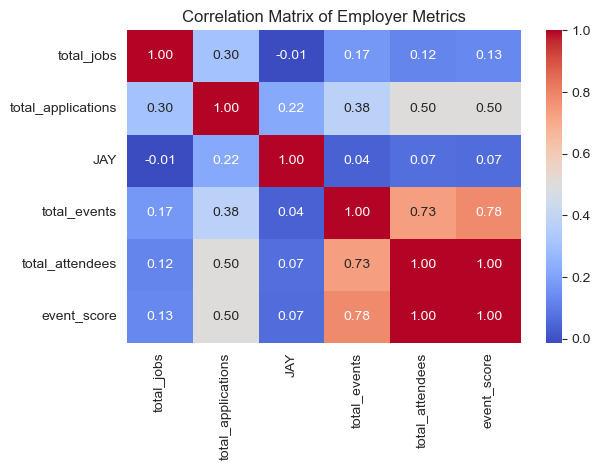

In [26]:
# -----------------------------
# Correlation Heatmap (New)
# -----------------------------

corr_cols = ['total_jobs','total_applications','JAY','total_events','total_attendees','event_score']
corr = employer_inf[corr_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Employer Metrics")
plt.tight_layout()
plt.show()

## KPI Engineering Extension
Added by: Abigail Merage

Builds on `employer_inf` to add missing KPIs:
- **EAY** – Event Attendance Yield (corrected dedup via `events_id`)
- **EEB** – Employer Engagement Breadth
- **EEC** – Unified Engagement Consistency (jobs + events combined)
- **ACI** – Application Concentration Index
- **SSI** – Salary Signaling Index (exploratory)
- **EEIS** – Composite Employer Engagement Intensity Score
- Employer type enrichment + segmentation visuals

### Event Attendance Yield (EAY)
**EAY = Student Attendees / Events Hosted**

Recomputes event counts using `events_id.nunique()` per employer, mirroring how `total_jobs` uses `jobs_id.nunique()`. The existing `total_events` column uses `events_name.count()` on raw rows, which can overcount when an employer appears across multiple job rows in the joined dataset.

In [27]:
# EAY - Event Attendance Yield (deduplicated via events_id)
events_df = ep_joined.dropna(subset=['events_id']).copy()
events_df = events_df.drop_duplicates(subset=['employer_id', 'events_id'])

events_emp = events_df.groupby('employer_id').agg(
    total_events_dedup=('events_id', 'count'),
    total_attendees_dedup=('student_attendees_count', 'sum')
).reset_index()

events_emp['EAY'] = events_emp['total_attendees_dedup'] / events_emp['total_events_dedup']

employer_inf = employer_inf.merge(
    events_emp[['employer_id', 'total_events_dedup', 'total_attendees_dedup', 'EAY']],
    on='employer_id', how='left'
)

print('Top 10 employers by Event Attendance Yield (EAY):')
employer_inf[['employer_name', 'total_events', 'total_attendees', 'EAY']]\
    .sort_values('EAY', ascending=False).head(10)

Top 10 employers by Event Attendance Yield (EAY):


,employer_name,total_events,total_attendees,EAY
5066,year up,1.0,269.0,269.00
17188,newmark,1.0,255.0,255.00
32314,bartaco restaurants,1.0,224.0,224.00
21071,the goddard school of watertown and milton,1.0,223.0,223.00
7342,puma,1.0,220.0,220.00
1595,putnam investments,2.0,415.0,207.50
2245,asml,2.0,375.0,187.50
1477,"shell usa, inc.",1.0,186.0,186.00
42092,"questrom school of business, boston university",4.0,731.0,182.75
26727,christian dior inc.,2.0,361.0,180.50


### Employer Engagement Breadth (EEB)
**EEB = 1(Posted Jobs) + 1(Hosted Events)**

Binary indicator of how many Handshake channels an employer uses. EEB=2 means both jobs and events; EEB=1 means one channel only; EEB=0 means inactive.

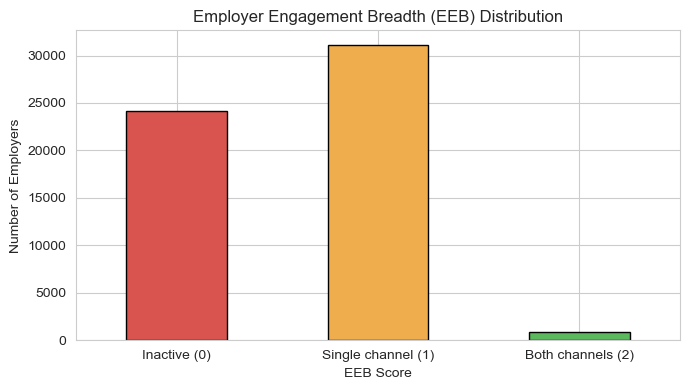

Inactive (0)          24111
Single channel (1)    31092
Both channels (2)       886
Name: count, dtype: int64


In [28]:
# EEB - Employer Engagement Breadth
employer_inf['EEB'] = (
    (employer_inf['total_jobs'] > 0).astype(int) +
    (employer_inf['total_events'].fillna(0) > 0).astype(int)
)

eeb_counts = employer_inf['EEB'].value_counts().sort_index()
labels = {0: 'Inactive (0)', 1: 'Single channel (1)', 2: 'Both channels (2)'}
eeb_counts.index = [labels.get(i, str(i)) for i in eeb_counts.index]

plt.figure(figsize=(7, 4))
eeb_counts.plot(kind='bar', color=['#d9534f', '#f0ad4e', '#5cb85c'], edgecolor='black')
plt.title('Employer Engagement Breadth (EEB) Distribution')
plt.xlabel('EEB Score')
plt.ylabel('Number of Employers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(eeb_counts)

### Employer Engagement Consistency (EEC) - Unified
**EEC = Active Years (jobs OR events) / Years Since First Activity**

Pools calendar years from both unique job postings and unique events per employer. This is the unified version of the separate `consistency_jobs` and `consistency_events` columns computed above. An employer that posted jobs in 2020 and hosted events in 2022 gets credit for both years in the numerator.

In [29]:
# EEC - Unified Engagement Consistency
jobs_df2 = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['employer_id', 'jobs_id']).copy()
jobs_df2['activity_year'] = pd.to_datetime(jobs_df2['job_creation_date'], errors='coerce').dt.year
job_years = jobs_df2[['employer_id', 'activity_year']].dropna()

events_df3 = ep_joined.dropna(subset=['events_id']).drop_duplicates(subset=['employer_id', 'events_id']).copy()
events_df3['activity_year'] = pd.to_datetime(events_df3['event_date'], errors='coerce').dt.year
event_years = events_df3[['employer_id', 'activity_year']].dropna()

all_years = pd.concat([job_years, event_years], ignore_index=True).drop_duplicates()

years_summary = all_years.groupby('employer_id')['activity_year'].agg(
    active_years_unified='nunique',
    first_year='min',
    last_year='max'
).reset_index()

years_summary['years_span'] = years_summary['last_year'] - years_summary['first_year'] + 1
years_summary['EEC'] = years_summary['active_years_unified'] / years_summary['years_span']

employer_inf = employer_inf.merge(
    years_summary[['employer_id', 'active_years_unified', 'years_span', 'EEC']],
    on='employer_id', how='left'
)

print(f"Employers with EEC = 1.0 (active every year in span): {(employer_inf['EEC'] == 1.0).sum()}")
print(f"Mean EEC: {employer_inf['EEC'].mean():.3f}")
employer_inf[['employer_name', 'active_years_unified', 'years_span', 'EEC']]\
    .sort_values('EEC', ascending=False).head(10)

Employers with EEC = 1.0 (active every year in span): 27413
Mean EEC: 0.955


,employer_name,active_years_unified,years_span,EEC
0,von maur,2.0,2.0,1.0
39562,malta inc.,1.0,1.0,1.0
39593,fuel sales academy,1.0,1.0,1.0
39590,"fidelis investors, llc",2.0,2.0,1.0
39582,"texas enterprises, inc.",1.0,1.0,1.0
39581,the farm school,1.0,1.0,1.0
39577,sharper shape,1.0,1.0,1.0
39576,"somos innovation, llc",1.0,1.0,1.0
39573,seaworld parks & entertainment,2.0,2.0,1.0
39572,genie healthcare,1.0,1.0,1.0


### Application Concentration Index (ACI)
**ACI = max(Applications per Job) / Total Applications**

Measures whether student interest is spread evenly across postings or concentrated in one job. ACI = 1.0 means all applications went to a single posting. Low ACI means student interest is distributed broadly. Computed only for employers with total_applications > 0.

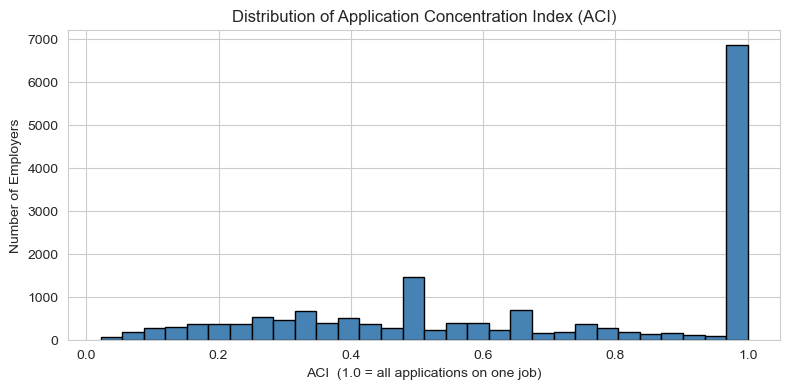

Median ACI: 0.667
Employers with ACI = 1.0: 6829  (39.3% of employers with applications)


In [30]:
# ACI - Application Concentration Index
jobs_aci = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['employer_id', 'jobs_id']).copy()

aci_agg = jobs_aci.groupby('employer_id').agg(
    max_apps_job=('applications_count', 'max'),
    total_apps_check=('applications_count', 'sum')
).reset_index()

aci_agg['ACI'] = np.where(
    aci_agg['total_apps_check'] > 0,
    aci_agg['max_apps_job'] / aci_agg['total_apps_check'],
    np.nan
)

employer_inf = employer_inf.merge(aci_agg[['employer_id', 'ACI']], on='employer_id', how='left')

aci_valid = employer_inf['ACI'].dropna()
plt.figure(figsize=(8, 4))
plt.hist(aci_valid, bins=30, edgecolor='black', color='steelblue')
plt.title('Distribution of Application Concentration Index (ACI)')
plt.xlabel('ACI  (1.0 = all applications on one job)')
plt.ylabel('Number of Employers')
plt.tight_layout()
plt.show()

print(f"Median ACI: {aci_valid.median():.3f}")
print(f"Employers with ACI = 1.0: {(aci_valid == 1.0).sum()} ",
      f"({100*(aci_valid==1.0).mean():.1f}% of employers with applications)")

### Salary Signaling Index (SSI)
**SSI = Avg Salary Midpoint x JAY**

Shows whether compensation levels correlate with attracting student applications. Salary midpoint = (min_salary + max_salary) / 2 per unique job. Zero-salary rows excluded (likely missing data). > Treated as exploratory due to known salary data quality issues from Milestone 1.

In [31]:
# SSI - Salary Signaling Index (corrected)
# Applies Handshake salary guidance:
# - min == max → hourly wage, annualized (x 2080)
# - min != max → already annualized range, take midpoint
# - null or zero → employer opted out, excluded
# - outliers → cap at $10k–$500k annualized

jobs_sal = ep_joined.dropna(subset=['jobs_id'])\
    .drop_duplicates(subset=['employer_id', 'jobs_id']).copy()

# Drop rows where both salary fields are null (employer opted out)
jobs_sal = jobs_sal[jobs_sal['min_salary'].notna() | jobs_sal['max_salary'].notna()]

# Identify hourly vs annualized per Handshake spec
jobs_sal['is_hourly'] = jobs_sal['min_salary'] == jobs_sal['max_salary']

# Compute salary midpoint correctly
jobs_sal['salary_mid'] = np.where(
    jobs_sal['is_hourly'],
    jobs_sal['min_salary'] * 2080,                                          # annualize hourly
    (jobs_sal['min_salary'].fillna(jobs_sal['max_salary']) +                # handle one-sided nulls
     jobs_sal['max_salary'].fillna(jobs_sal['min_salary'])) / 2
)

# Remove zeros and outliers
jobs_sal = jobs_sal[
    (jobs_sal['salary_mid'] > 0) &
    (jobs_sal['salary_mid'] >= 10000) &
    (jobs_sal['salary_mid'] <= 500000)
]

# Diagnostics
total = len(jobs_sal)
print(f"Jobs with valid salary after cleaning: {total:,}")
print(f"  Hourly (annualized):  {jobs_sal['is_hourly'].sum():,} ({100*jobs_sal['is_hourly'].sum()/total:.1f}%)")
print(f"  Salaried range:       {(~jobs_sal['is_hourly']).sum():,} ({100*(~jobs_sal['is_hourly']).sum()/total:.1f}%)")
print(f"  Salary range:         ${jobs_sal['salary_mid'].min():,.0f} – ${jobs_sal['salary_mid'].max():,.0f}")
print(f"  Median salary mid:    ${jobs_sal['salary_mid'].median():,.0f}")
print()

# Aggregate to employer level
avg_salary = jobs_sal.groupby('employer_id')['salary_mid'].mean().reset_index()
avg_salary.columns = ['employer_id', 'avg_salary_mid']

# Drop existing avg_salary_mid if re-running
if 'avg_salary_mid' in employer_inf.columns:
    employer_inf = employer_inf.drop(columns=['avg_salary_mid', 'SSI'], errors='ignore')

employer_inf = employer_inf.merge(avg_salary, on='employer_id', how='left')
employer_inf['SSI'] = employer_inf['avg_salary_mid'] * employer_inf['JAY']

print('Top 10 employers by Salary Signaling Index (SSI):')
employer_inf.dropna(subset=['SSI']).sort_values('SSI', ascending=False)\
    [['employer_name', 'avg_salary_mid', 'JAY', 'SSI']].head(10)

Jobs with valid salary after cleaning: 169,548
  Hourly (annualized):  75,930 (44.8%)
  Salaried range:       93,618 (55.2%)
  Salary range:         $10,000 – $500,000
  Median salary mid:    $55,000

Top 10 employers by Salary Signaling Index (SSI):


,employer_name,avg_salary_mid,JAY,SSI
3283,delta partners,95000.000000,431.000000,4.094500e+07
53183,fundamental research labs,200000.000000,181.000000,3.620000e+07
54173,encora therapeutics,62400.000000,283.000000,1.765920e+07
52261,ikigai labs,136666.666667,114.666667,1.567111e+07
32951,aquatic,175000.000000,71.000000,1.242500e+07
42155,headway,214994.666667,56.000000,1.203970e+07
9805,cogo labs,136945.000000,86.333333,1.182292e+07
3606,newbury partners,141667.000000,81.666667,1.156947e+07
51965,marston limited,92500.000000,122.000000,1.128500e+07
52509,dugree,416000.000000,27.000000,1.123200e+07


### Employer Engagement Intensity Score (EEIS)
**EEIS = w1(Jobs) + w2(Events) + w3(Applications) + w4(Attendees)**

Composite engagement score. Each of the four input channels is min-max scaled to [0,1] then combined with equal weights (0.25 each). Reflects how deeply an employer engages with BU students across multiple Handshake channels.

In [32]:
# EEIS - Composite Employer Engagement Intensity Score
from sklearn.preprocessing import MinMaxScaler

eeis_input = employer_inf[['total_jobs', 'total_events_dedup', 'total_applications', 'total_attendees_dedup']].fillna(0)

scaler = MinMaxScaler()
normed = scaler.fit_transform(eeis_input)

w1, w2, w3, w4 = 0.25, 0.25, 0.25, 0.25
employer_inf['EEIS'] = w1*normed[:,0] + w2*normed[:,1] + w3*normed[:,2] + w4*normed[:,3]

print('Top 10 employers by EEIS (composite engagement):')
employer_inf.sort_values('EEIS', ascending=False)\
    [['employer_name', 'total_jobs', 'total_events_dedup', 'total_applications', 'total_attendees_dedup', 'EEIS']].head(10)

Top 10 employers by EEIS (composite engagement):


,employer_name,total_jobs,total_events_dedup,total_applications,total_attendees_dedup,EEIS
135,ey,383,314.0,2723.0,2404.0,0.564389
1731,jpmorganchase,985,109.0,9732.0,1366.0,0.443114
2461,amazon,795,61.0,14015.0,989.0,0.434246
4947,pwc,221,173.0,2615.0,2261.0,0.428640
759,morgan stanley,450,185.0,5346.0,1386.0,0.405373
921,mckinsey & company,178,165.0,4198.0,1797.0,0.400480
838,goldman sachs,164,129.0,6919.0,1596.0,0.398874
32,kpmg llp,140,158.0,4326.0,1535.0,0.368375
728,capital one,27,246.0,549.0,1164.0,0.327816
46,deloitte,213,81.0,2654.0,1890.0,0.317176


In [33]:
# Top 10 employers by EEIS - using deduplicated columns
print('Top 10 employers by EEIS (composite engagement):')
top_eeis = employer_inf.sort_values('EEIS', ascending=False)[
    ['employer_name', 'total_jobs', 'total_events_dedup', 'total_applications', 'total_attendees_dedup', 'EEIS']
].head(10)
display(top_eeis)

print()
print("EEIS Definition:")
print("=" * 60)
print("Employer Engagement Intensity Score (EEIS)")
print("EEIS = 0.25(Jobs) + 0.25(Events) + 0.25(Applications) + 0.25(Attendees)")
print()
print("Each channel is min-max scaled to [0,1] before weighting.")
print("EEIS = 1.0 → most engaged employer in dataset across all channels")
print("EEIS = 0.0 → no activity across any channel")
print()
print("Interpretation of top employers:")
for _, row in top_eeis.iterrows():
    dominant = max(
        ('job postings', row['total_jobs']),
        ('events', row['total_events_dedup']),
        ('applications', row['total_applications']),
        ('attendees', row['total_attendees_dedup']),
        key=lambda x: x[1]
    )
    print(f"  {row['employer_name']:<25} EEIS={row['EEIS']:.3f} | driven by {dominant[0]} ({int(dominant[1]):,})")

Top 10 employers by EEIS (composite engagement):


,employer_name,total_jobs,total_events_dedup,total_applications,total_attendees_dedup,EEIS
135,ey,383,314.0,2723.0,2404.0,0.564389
1731,jpmorganchase,985,109.0,9732.0,1366.0,0.443114
2461,amazon,795,61.0,14015.0,989.0,0.434246
4947,pwc,221,173.0,2615.0,2261.0,0.428640
759,morgan stanley,450,185.0,5346.0,1386.0,0.405373
921,mckinsey & company,178,165.0,4198.0,1797.0,0.400480
838,goldman sachs,164,129.0,6919.0,1596.0,0.398874
32,kpmg llp,140,158.0,4326.0,1535.0,0.368375
728,capital one,27,246.0,549.0,1164.0,0.327816
46,deloitte,213,81.0,2654.0,1890.0,0.317176



EEIS Definition:
Employer Engagement Intensity Score (EEIS)
EEIS = 0.25(Jobs) + 0.25(Events) + 0.25(Applications) + 0.25(Attendees)

Each channel is min-max scaled to [0,1] before weighting.
EEIS = 1.0 → most engaged employer in dataset across all channels
EEIS = 0.0 → no activity across any channel

Interpretation of top employers:
  ey                        EEIS=0.564 | driven by applications (2,723)
  jpmorganchase             EEIS=0.443 | driven by applications (9,732)
  amazon                    EEIS=0.434 | driven by applications (14,015)
  pwc                       EEIS=0.429 | driven by applications (2,615)
  morgan stanley            EEIS=0.405 | driven by applications (5,346)
  mckinsey & company        EEIS=0.400 | driven by applications (4,198)
  goldman sachs             EEIS=0.399 | driven by applications (6,919)
  kpmg llp                  EEIS=0.368 | driven by applications (4,326)
  capital one               EEIS=0.328 | driven by attendees (1,164)
  deloitte        

### Employer Type Enrichment
Merges `employer_type` and size from `ep_base_cleaned.csv` to enable engagement breakdowns by industry sector.

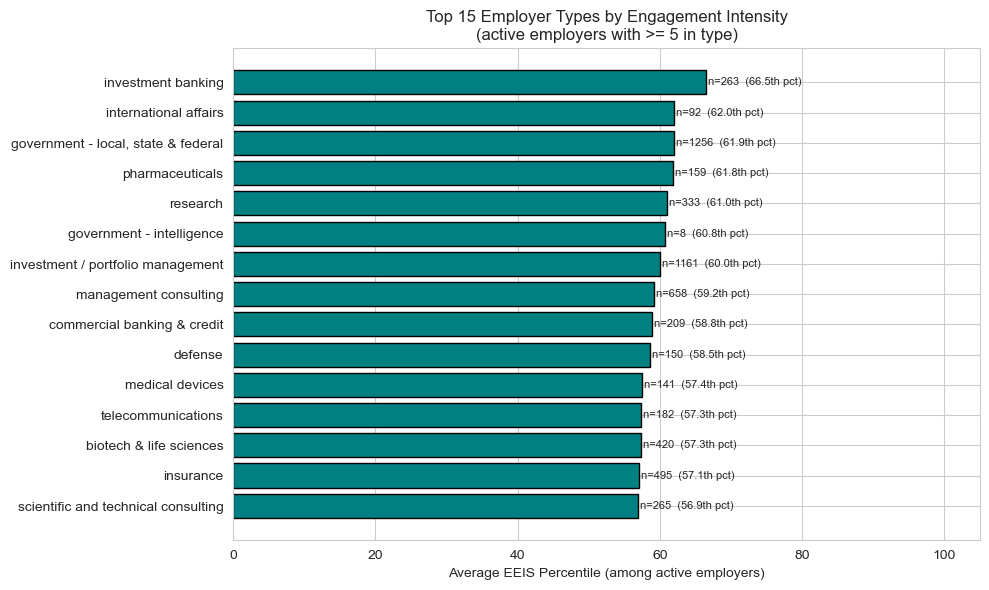

                      employer_type  avg_EEIS_pct  median_EEIS_pct  count
                 investment banking          66.5             76.9    263
              international affairs          62.0             63.9     92
government - local, state & federal          61.9             66.2   1256
                    pharmaceuticals          61.8             65.8    159
                           research          61.0             66.4    333
          government - intelligence          60.8             61.8      8
  investment / portfolio management          60.0             64.5   1161
              management consulting          59.2             63.2    658
        commercial banking & credit          58.8             62.5    209
                            defense          58.5             62.7    150
                    medical devices          57.4             62.3    141
                 telecommunications          57.3             58.6    182
            biotech & life sciences   

In [53]:
# Employer type enrichment from ep_base_cleaned
ep_base = pd.read_csv(os.path.join(DATA_DIR, 'ep_base_cleaned.csv'), low_memory=False)
base_attrs = ep_base[['employer_id', 'employer_type', 'employer_size_min', 'employer_size_max']]\
    .drop_duplicates(subset=['employer_id']).copy()
base_attrs['employer_size_mid'] = (
    base_attrs['employer_size_min'].fillna(0) + base_attrs['employer_size_max'].fillna(0)
) / 2

# Drop existing enrichment columns if already merged (prevents duplicate column error on re-run)
cols_to_drop = ['employer_type', 'employer_size_min', 'employer_size_max', 'employer_size_mid']
employer_inf = employer_inf.drop(columns=[c for c in cols_to_drop if c in employer_inf.columns])
employer_inf = employer_inf.merge(base_attrs, on='employer_id', how='left')

# Filter to active employers only
active_employers = employer_inf[
    (employer_inf['total_jobs'] > 0) |
    (employer_inf['total_events_dedup'].fillna(0) > 0)
].copy()

# Percentile within active employers
# Use whichever EEIS column exists
eeis_col = 'EEIS_equal' if 'EEIS_equal' in active_employers.columns else 'EEIS'
active_employers['EEIS_pct'] = active_employers[eeis_col].rank(pct=True) * 100

# Average EEIS percentile by employer type (min 5 employers per type)
type_eeis_pct = active_employers.dropna(subset=['employer_type', 'EEIS_pct'])\
    .groupby('employer_type').agg(
        avg_EEIS_pct=('EEIS_pct', 'mean'),
        median_EEIS_pct=('EEIS_pct', 'median'),
        count=('employer_id', 'count')
    ).reset_index()\
    .query('count >= 5')\
    .sort_values('avg_EEIS_pct', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(type_eeis_pct['employer_type'][::-1],
               type_eeis_pct['avg_EEIS_pct'][::-1],
               color='teal', edgecolor='black')

for bar, (_, row) in zip(bars, type_eeis_pct[::-1].iterrows()):
    ax.text(bar.get_width() + 0.3,
            bar.get_y() + bar.get_height()/2,
            f"n={int(row['count'])}  ({row['avg_EEIS_pct']:.1f}th pct)",
            va='center', fontsize=8)

ax.set_xlabel('Average EEIS Percentile (among active employers)')
ax.set_title('Top 15 Employer Types by Engagement Intensity\n(active employers with >= 5 in type)')
ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

print(type_eeis_pct[['employer_type', 'avg_EEIS_pct', 'median_EEIS_pct', 'count']].round(1).to_string(index=False))

## Average EEIS by Employer Type — Notes

**count >= 5 filter:** Excludes employer types with fewer than 5 active employers to prevent a single outlier from skewing the sector average.

**Average EEIS:** Mean engagement score across all active employers in that sector. A higher value means employers in that sector are consistently more active across jobs, events, applications, and attendees on Handshake - relative to the most engaged employer in the dataset.

**Key insight:** Investment banking leads all sectors (0.0086), followed by tech hardware, consulting, and accounting. Government has the most employers (n=1,256) but lower average engagement per employer.

### Employer Segmentation: EEB x EEC
Segments employers by breadth (channels used) and consistency (regularity of engagement). Four quadrants for the CCD slide deck:
- **Core Partners**: EEB=2, high EEC (both channels, consistent)
- **Sporadic Multi-Channel**: EEB=2, low EEC (both channels, irregular)
- **Loyal Single-Channel**: EEB=1, high EEC (one channel, consistent)
- **Peripheral**: EEB=0 or low EEC (minimal engagement)

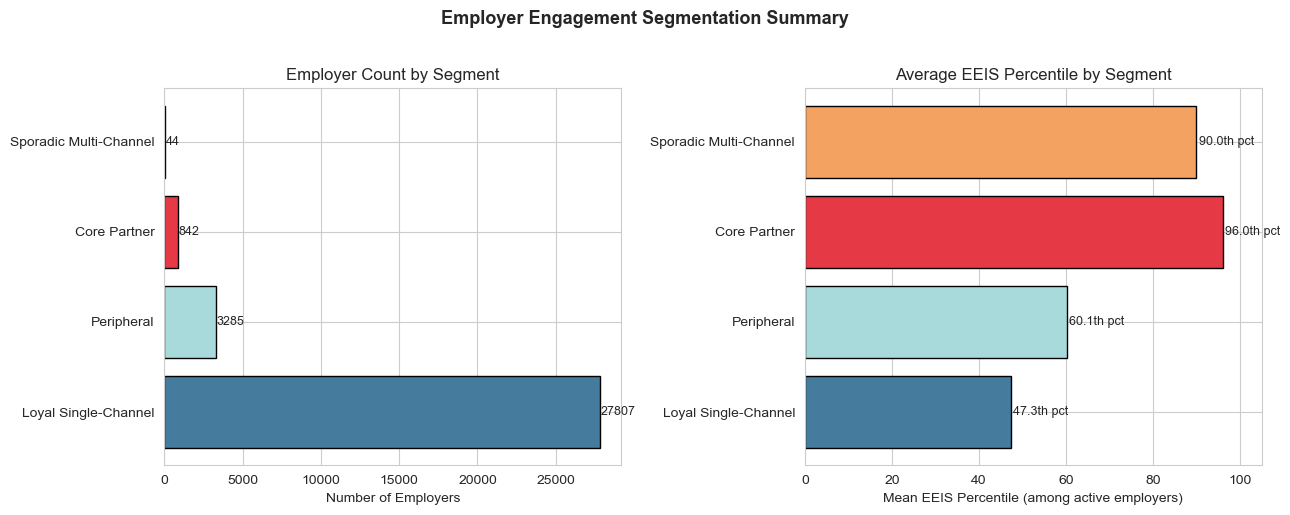


Segment Summary:


,count,avg_EEIS_pct,median_EEIS_pct,avg_EEC,avg_jobs
segment,,,,,
Core Partner,842,96.00,97.77,0.99,149.28
Loyal Single-Channel,27807,47.35,46.26,0.99,14.85
Peripheral,3285,60.13,59.16,0.63,7.15
Sporadic Multi-Channel,44,89.99,91.21,0.63,11.59



Top 10 Core Partners (by EEIS score):


,employer_name,total_jobs,total_events_dedup,total_applications,total_attendees_dedup,EEIS
0,ey,383,314.0,2723.0,2404.0,0.564
1,jpmorganchase,985,109.0,9732.0,1366.0,0.443
2,amazon,795,61.0,14015.0,989.0,0.434
3,pwc,221,173.0,2615.0,2261.0,0.429
4,morgan stanley,450,185.0,5346.0,1386.0,0.405
5,mckinsey & company,178,165.0,4198.0,1797.0,0.400
6,goldman sachs,164,129.0,6919.0,1596.0,0.399
7,kpmg llp,140,158.0,4326.0,1535.0,0.368
8,capital one,27,246.0,549.0,1164.0,0.328
9,deloitte,213,81.0,2654.0,1890.0,0.317


In [54]:
seg = employer_inf.dropna(subset=['EEC', 'EEB', 'EEIS']).copy()
seg = seg[seg['EEB'] > 0]

seg['EEIS_pct'] = seg['EEIS'].rank(pct=True) * 100

eec_threshold = 0.8
seg['segment'] = 'Loyal Single-Channel'
seg.loc[(seg['EEB'] == 2) & (seg['EEC'] >= eec_threshold), 'segment'] = 'Core Partner'
seg.loc[(seg['EEB'] == 2) & (seg['EEC'] < eec_threshold), 'segment'] = 'Sporadic Multi-Channel'
seg.loc[(seg['EEB'] < 2) & (seg['EEC'] < eec_threshold), 'segment'] = 'Peripheral'

colors = {'Core Partner': '#e63946', 'Sporadic Multi-Channel': '#f4a261',
          'Loyal Single-Channel': '#457b9d', 'Peripheral': '#a8dadc'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

seg_counts = seg['segment'].value_counts()
bar_colors = [colors[s] for s in seg_counts.index]
axes[0].barh(seg_counts.index, seg_counts.values, color=bar_colors, edgecolor='black')
axes[0].set_title('Employer Count by Segment')
axes[0].set_xlabel('Number of Employers')
for i, v in enumerate(seg_counts.values):
    axes[0].text(v + 50, i, str(v), va='center', fontsize=9)

seg_eeis_pct = seg.groupby('segment')['EEIS_pct'].mean().reindex(seg_counts.index)
bar_colors2 = [colors[s] for s in seg_eeis_pct.index]
axes[1].barh(seg_eeis_pct.index, seg_eeis_pct.values, color=bar_colors2, edgecolor='black')
axes[1].set_title('Average EEIS Percentile by Segment')
axes[1].set_xlabel('Mean EEIS Percentile (among active employers)')
axes[1].set_xlim(0, 105)
for i, v in enumerate(seg_eeis_pct.values):
    axes[1].text(v + 0.5, i, f'{v:.1f}th pct', va='center', fontsize=9)

plt.suptitle('Employer Engagement Segmentation Summary', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nSegment Summary:")
summary = seg.groupby('segment').agg(
    count=('EEIS', 'count'),
    avg_EEIS_pct=('EEIS_pct', 'mean'),
    median_EEIS_pct=('EEIS_pct', 'median'),
    avg_EEC=('EEC', 'mean'),
    avg_jobs=('total_jobs', 'mean'),
).round(2)
display(summary)

print("\nTop 10 Core Partners (by EEIS score):")
top_core = seg[seg['segment'] == 'Core Partner']\
    .sort_values('EEIS', ascending=False).head(10)[
    ['employer_name', 'total_jobs', 'total_events_dedup',
     'total_applications', 'total_attendees_dedup', 'EEIS']
].reset_index(drop=True)
display(top_core.round(3))

### Full Employer KPI Summary Table
Consolidated view of all KPIs. Sorted by EEIS descending.

In [37]:
# Full employer KPI summary
kpi_cols = [
    'employer_name', 'employer_type',
    'total_jobs', 'total_applications', 'JAY',
    'total_events', 'total_attendees', 'EAY',
    'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS'
]
available = [c for c in kpi_cols if c in employer_inf.columns]
kpi_summary = employer_inf[available].sort_values('EEIS', ascending=False)
print(f'Total employers in KPI table: {len(kpi_summary)}')
kpi_summary.head(20)

Total employers in KPI table: 56089


,employer_name,employer_type,total_jobs,total_applications,JAY,total_events,total_attendees,EAY,EEB,EEC,ACI,avg_salary_mid,SSI,EEIS
135,ey,accounting,383,2723.0,7.109661,314.0,2404.0,7.656051,2,1.0,0.030114,79093.620339,5.623288e+05,0.564389
1731,jpmorganchase,financial services,985,9732.0,9.880203,109.0,1366.0,12.532110,2,1.0,0.034423,81271.011275,8.029741e+05,0.443114
2461,amazon,internet & software,795,14015.0,17.628931,61.0,989.0,16.213115,2,1.0,0.032394,58425.773099,1.029984e+06,0.434246
4947,pwc,accounting,221,2615.0,11.832579,173.0,2261.0,13.069364,2,1.0,0.041300,89280.434783,1.056418e+06,0.428640
759,morgan stanley,investment banking,450,5346.0,11.880000,185.0,1386.0,7.491892,2,1.0,0.027123,88620.940000,1.052817e+06,0.405373
921,mckinsey & company,management consulting,178,4198.0,23.584270,165.0,1797.0,10.890909,2,1.0,0.061934,151298.275517,3.568259e+06,0.400480
838,goldman sachs,investment banking,164,6919.0,42.189024,129.0,1596.0,12.372093,2,1.0,0.076023,91849.999000,3.875062e+06,0.398874
32,kpmg llp,accounting,140,4326.0,30.900000,158.0,1535.0,9.715190,2,1.0,0.073509,39260.000000,1.213134e+06,0.368375
728,capital one,commercial banking & credit,27,549.0,20.333333,246.0,1164.0,4.731707,2,1.0,0.262295,110000.000000,2.236667e+06,0.327816
46,deloitte,management consulting,213,2654.0,12.460094,81.0,1890.0,23.333333,2,1.0,0.086662,77641.800000,9.674241e+05,0.317176


In [38]:
# Export employer KPI table 
export_cols = [c for c in [
    'employer_name', 'employer_type',
    'total_jobs', 'total_applications', 'JAY',
    'total_events_dedup', 'total_attendees_dedup', 'EAY',
    'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS'
] if c in employer_inf.columns]

employer_inf.reset_index()[['employer_id'] + export_cols].to_csv(
    os.path.join(DATA_DIR, 'employer_kpi.csv'), index=False
)

print(f"Exported employer_kpi.csv")
print(f"Rows: {len(employer_inf):,}")
print(f"Columns: {export_cols}")

Exported employer_kpi.csv
Rows: 56,089
Columns: ['employer_name', 'employer_type', 'total_jobs', 'total_applications', 'JAY', 'total_events_dedup', 'total_attendees_dedup', 'EAY', 'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS']


# Some Unanswered Questions by the KPIs

## Event Type Analysis
Identifies common event types by parsing `events_name` into categories. Addresses task: *Identify highly engaged employers, common event types, and engagement trends.*

Event Type Summary:


,event_type,event_count,total_attendees,avg_attendees
4,Other,4979,28437.0,5.71
1,Info Session,1923,11141.0,5.79
7,Workshop/Webinar,751,3435.0,4.57
5,Panel/Speaker,479,5299.0,11.06
6,Recruiting/Interview,371,2476.0,6.67
0,Career Fair,346,2093.0,6.05
3,Open House/Coffee Chat,292,2172.0,7.44
2,Networking,219,3306.0,15.10


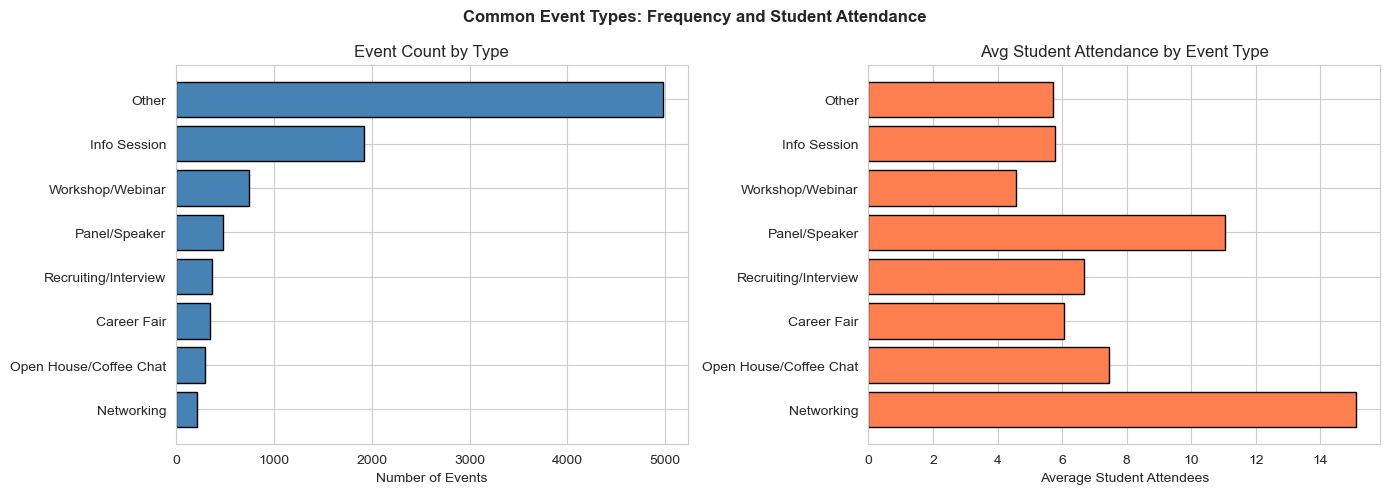

In [39]:
# Event type categorization from events_name
events_clean = ep_joined.dropna(subset=['events_id']).drop_duplicates(subset=['events_id']).copy()
events_clean['events_name_lower'] = events_clean['events_name'].str.lower().str.strip()

def categorize_event(name):
    if any(k in name for k in ['career fair', 'job fair', 'hiring fair']):
        return 'Career Fair'
    elif any(k in name for k in ['info session', 'information session', 'infosession']):
        return 'Info Session'
    elif any(k in name for k in ['networking', 'network']):
        return 'Networking'
    elif any(k in name for k in ['workshop', 'seminar', 'training', 'webinar']):
        return 'Workshop/Webinar'
    elif any(k in name for k in ['interview', 'recruiting', 'recruitment']):
        return 'Recruiting/Interview'
    elif any(k in name for k in ['panel', 'speaker', 'talk', 'presentation']):
        return 'Panel/Speaker'
    elif any(k in name for k in ['open house', 'office hour', 'coffee chat']):
        return 'Open House/Coffee Chat'
    else:
        return 'Other'

events_clean['event_type'] = events_clean['events_name_lower'].apply(categorize_event)

# Count and attendees per event type
event_type_summary = events_clean.groupby('event_type').agg(
    event_count=('events_id', 'count'),
    total_attendees=('student_attendees_count', 'sum'),
    avg_attendees=('student_attendees_count', 'mean')
).reset_index().sort_values('event_count', ascending=False)

print('Event Type Summary:')
display(event_type_summary.round(2))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(event_type_summary['event_type'][::-1],
             event_type_summary['event_count'][::-1],
             color='steelblue', edgecolor='black')
axes[0].set_xlabel('Number of Events')
axes[0].set_title('Event Count by Type')

axes[1].barh(event_type_summary['event_type'][::-1],
             event_type_summary['avg_attendees'][::-1],
             color='coral', edgecolor='black')
axes[1].set_xlabel('Average Student Attendees')
axes[1].set_title('Avg Student Attendance by Event Type')

plt.suptitle('Common Event Types: Frequency and Student Attendance', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Engagement Trends Over Time
Year-over-year trends for job postings, applications, and event hosting. Addresses task: *Identify engagement trends* and *Analyze employer activity on Handshake.*

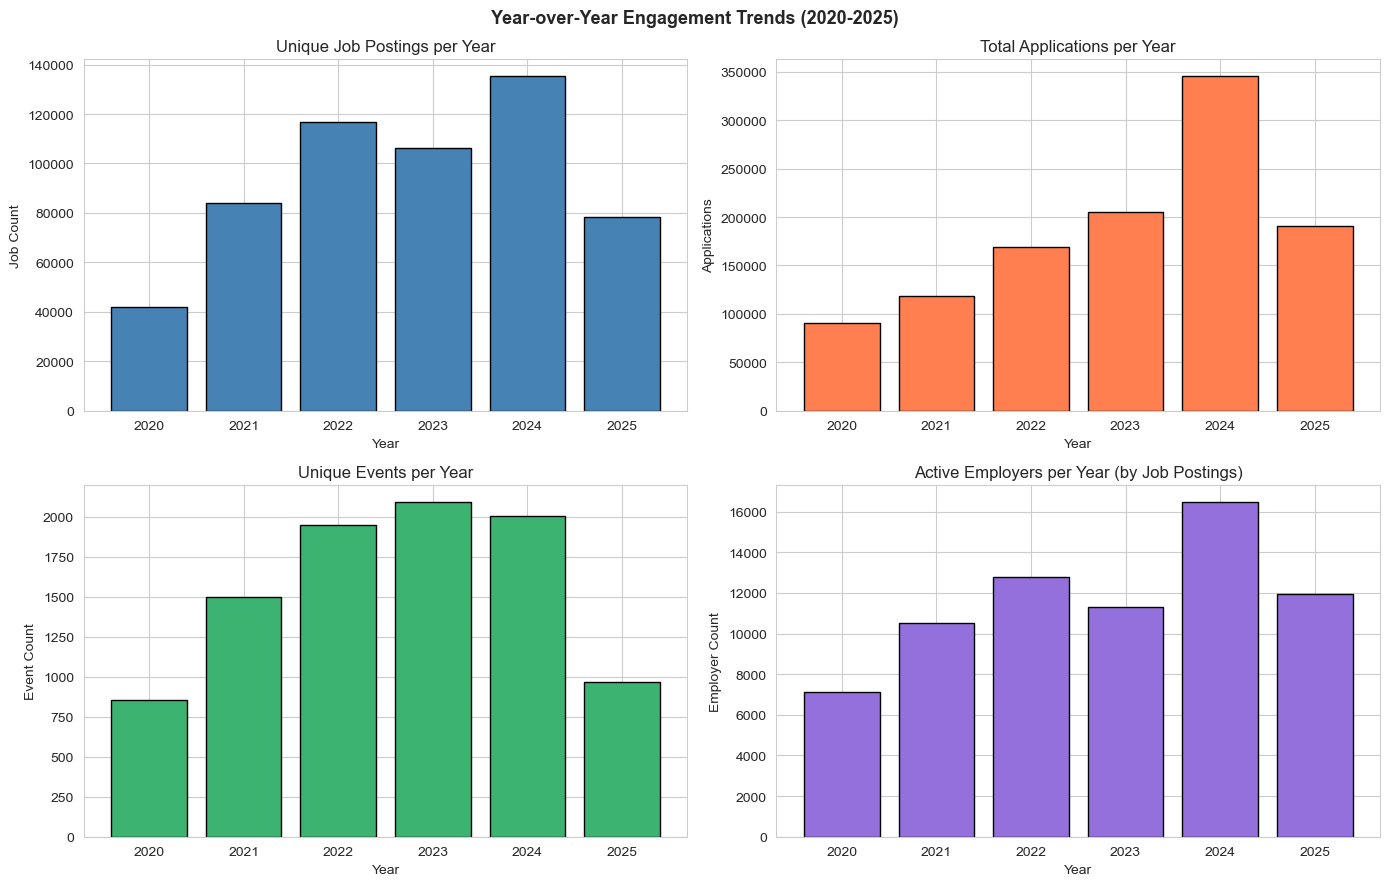

In [40]:
# Year-over-year engagement trends

# Jobs and applications by year (unique jobs)
jobs_yearly = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['jobs_id']).copy()
jobs_yearly['year'] = pd.to_datetime(jobs_yearly['job_creation_date'], errors='coerce').dt.year
jobs_by_year = jobs_yearly.groupby('year').agg(
    unique_jobs=('jobs_id', 'count'),
    total_applications=('applications_count', 'sum'),
    active_employers=('employer_id', 'nunique')
).reset_index().dropna(subset=['year'])
jobs_by_year['year'] = jobs_by_year['year'].astype(int)

# Events by year (unique events)
events_yearly = ep_joined.dropna(subset=['events_id']).drop_duplicates(subset=['events_id']).copy()
events_yearly['year'] = pd.to_datetime(events_yearly['event_date'], errors='coerce').dt.year
events_by_year = events_yearly.groupby('year').agg(
    unique_events=('events_id', 'count'),
    total_attendees=('student_attendees_count', 'sum')
).reset_index().dropna(subset=['year'])
events_by_year['year'] = events_by_year['year'].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Jobs posted per year
axes[0,0].bar(jobs_by_year['year'], jobs_by_year['unique_jobs'], color='steelblue', edgecolor='black')
axes[0,0].set_title('Unique Job Postings per Year')
axes[0,0].set_xlabel('Year')
axes[0,0].set_ylabel('Job Count')

# Applications per year
axes[0,1].bar(jobs_by_year['year'], jobs_by_year['total_applications'], color='coral', edgecolor='black')
axes[0,1].set_title('Total Applications per Year')
axes[0,1].set_xlabel('Year')
axes[0,1].set_ylabel('Applications')

# Events per year
axes[1,0].bar(events_by_year['year'], events_by_year['unique_events'], color='mediumseagreen', edgecolor='black')
axes[1,0].set_title('Unique Events per Year')
axes[1,0].set_xlabel('Year')
axes[1,0].set_ylabel('Event Count')

# Active employers per year
axes[1,1].bar(jobs_by_year['year'], jobs_by_year['active_employers'], color='mediumpurple', edgecolor='black')
axes[1,1].set_title('Active Employers per Year (by Job Postings)')
axes[1,1].set_xlabel('Year')
axes[1,1].set_ylabel('Employer Count')

plt.suptitle('Year-over-Year Engagement Trends (2020-2025)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Student Engagement Analysis
Examines student engagement through event attendance and application behavior. Addresses task: *Examine student engagement through applications and event attendance.*

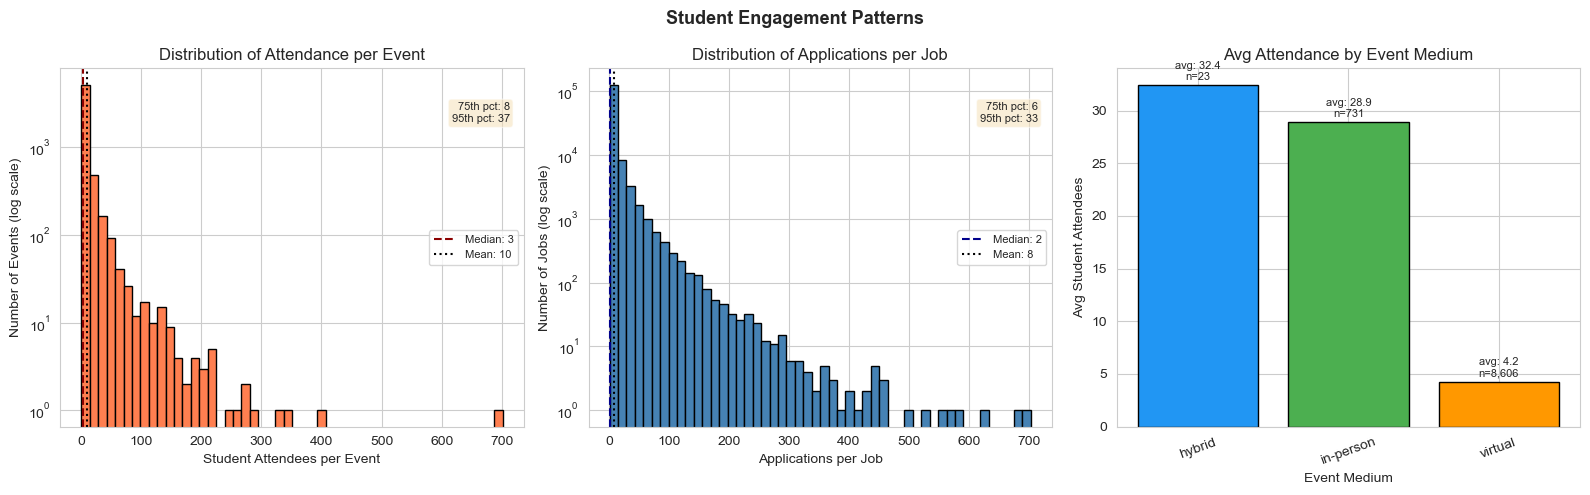

Attendance per event:
count    6038.0
mean        9.7
std        23.5
min         1.0
25%         1.0
50%         3.0
75%         8.0
max       701.0
Name: student_attendees_count, dtype: float64

Applications per job:
count    141912.0
mean          7.9
std          19.1
min           1.0
25%           1.0
50%           2.0
75%           6.0
max         703.0
Name: applications_count, dtype: float64

Event medium breakdown:
event_medium  avg_attendees  event_count
      hybrid      32.391304           23
   in-person      28.880985          731
     virtual       4.241459         8606


In [41]:
# Student engagement: attendance and application patterns

# Data prep
att_per_event = ep_joined.dropna(subset=['events_id'])\
    .drop_duplicates(subset=['events_id'])['student_attendees_count'].dropna()
att_per_event_filtered = att_per_event[att_per_event > 0]

apps_per_job = ep_joined.dropna(subset=['jobs_id'])\
    .drop_duplicates(subset=['jobs_id'])['applications_count'].dropna()
apps_per_job_filtered = apps_per_job[apps_per_job > 0]

medium_attendance = ep_joined.dropna(subset=['events_id', 'event_medium'])\
    .drop_duplicates(subset=['events_id'])\
    .groupby('event_medium')['student_attendees_count'].agg(['mean', 'count'])\
    .reset_index().sort_values('mean', ascending=False)

# Plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Attendance per event - log scale
axes[0].hist(att_per_event_filtered, bins=50, color='coral', edgecolor='black', log=True)
axes[0].set_xlabel('Student Attendees per Event')
axes[0].set_ylabel('Number of Events (log scale)')
axes[0].set_title('Distribution of Attendance per Event')
axes[0].axvline(att_per_event_filtered.median(), color='darkred', linestyle='--',
                label=f'Median: {att_per_event_filtered.median():.0f}')
axes[0].axvline(att_per_event_filtered.mean(), color='black', linestyle=':',
                label=f'Mean: {att_per_event_filtered.mean():.0f}')
axes[0].legend(fontsize=8)
p75 = att_per_event_filtered.quantile(0.75)
p95 = att_per_event_filtered.quantile(0.95)
axes[0].text(0.97, 0.85, f'75th pct: {p75:.0f}\n95th pct: {p95:.0f}',
             transform=axes[0].transAxes, ha='right', fontsize=8,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 2. Applications per job — log scale
axes[1].hist(apps_per_job_filtered, bins=50, color='steelblue', edgecolor='black', log=True)
axes[1].set_xlabel('Applications per Job')
axes[1].set_ylabel('Number of Jobs (log scale)')
axes[1].set_title('Distribution of Applications per Job')
axes[1].axvline(apps_per_job_filtered.median(), color='darkblue', linestyle='--',
                label=f'Median: {apps_per_job_filtered.median():.0f}')
axes[1].axvline(apps_per_job_filtered.mean(), color='black', linestyle=':',
                label=f'Mean: {apps_per_job_filtered.mean():.0f}')
axes[1].legend(fontsize=8)
p75_apps = apps_per_job_filtered.quantile(0.75)
p95_apps = apps_per_job_filtered.quantile(0.95)
axes[1].text(0.97, 0.85, f'75th pct: {p75_apps:.0f}\n95th pct: {p95_apps:.0f}',
             transform=axes[1].transAxes, ha='right', fontsize=8,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 3. Avg attendance by medium
bars = axes[2].bar(medium_attendance['event_medium'],
                   medium_attendance['mean'],
                   color=['#2196F3', '#4CAF50', '#FF9800'][:len(medium_attendance)],
                   edgecolor='black')
axes[2].set_xlabel('Event Medium')
axes[2].set_ylabel('Avg Student Attendees')
axes[2].set_title('Avg Attendance by Event Medium')
axes[2].tick_params(axis='x', rotation=20)
for bar, (_, row) in zip(bars, medium_attendance.iterrows()):
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f"avg: {row['mean']:.1f}\nn={int(row['count']):,}",
                 ha='center', va='bottom', fontsize=8)

plt.suptitle('Student Engagement Patterns', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary stats 
print("Attendance per event:")
print(att_per_event_filtered.describe().round(1))
print("\nApplications per job:")
print(apps_per_job_filtered.describe().round(1))
print("\nEvent medium breakdown:")
print(medium_attendance.rename(columns={'mean': 'avg_attendees', 'count': 'event_count'}).to_string(index=False))

---
# Extended Analysis Post Client Meeting: Segmentation by Employer Characteristics

Sections:
1. **ACI by job posting volume thresholds**: how concentration changes with employer size
2. **ACI by employer characteristics**: type, size, EEB segment, consistency
3. **EEIS with PCA-derived weights**: mathematically defensible alternative weighting
4. **JAY segmentation**: by employer type, size, EEB, EEC
5. **EAY segmentation**: by employer type, size, event medium
6. **EEC segmentation**: by employer type, size
7. **Event type analysis segmented**: by employer type and size
8. **YoY trends segmented**: by employer type
9. **Student engagement segmented**: by event medium and employer type

## 1. ACI by Job Posting Volume Threshold
ACI = max(applications on one job) / total applications. Employers with very few postings have artificially high ACI simply because there are fewer jobs to distribute applications across. This section filters by minimum posting count to show how concentration changes as we restrict to more active employers.

ACI Statistics by Minimum Posting Threshold:


,Filter,N Employers,Mean ACI,Median ACI,ACI=1.0 (%),ACI < 0.5 (%)
0,>= 1 job (w/ apps),17383,0.672,0.667,39.286,31.157
1,>= 3 jobs (52%),12365,0.559,0.500,21.181,43.801
2,>= 5 jobs (38%),9732,0.500,0.444,16.482,53.535
3,>= 10 jobs (24%),6462,0.421,0.333,11.746,66.543
4,>= 20 jobs (14%),4029,0.351,0.268,8.935,76.495
5,>= 50 jobs (6%),1949,0.267,0.190,5.490,86.147
6,>= 100 jobs (3%),1011,0.209,0.146,2.967,91.197
7,>= 200 jobs (1.5%),462,0.168,0.115,1.515,94.156


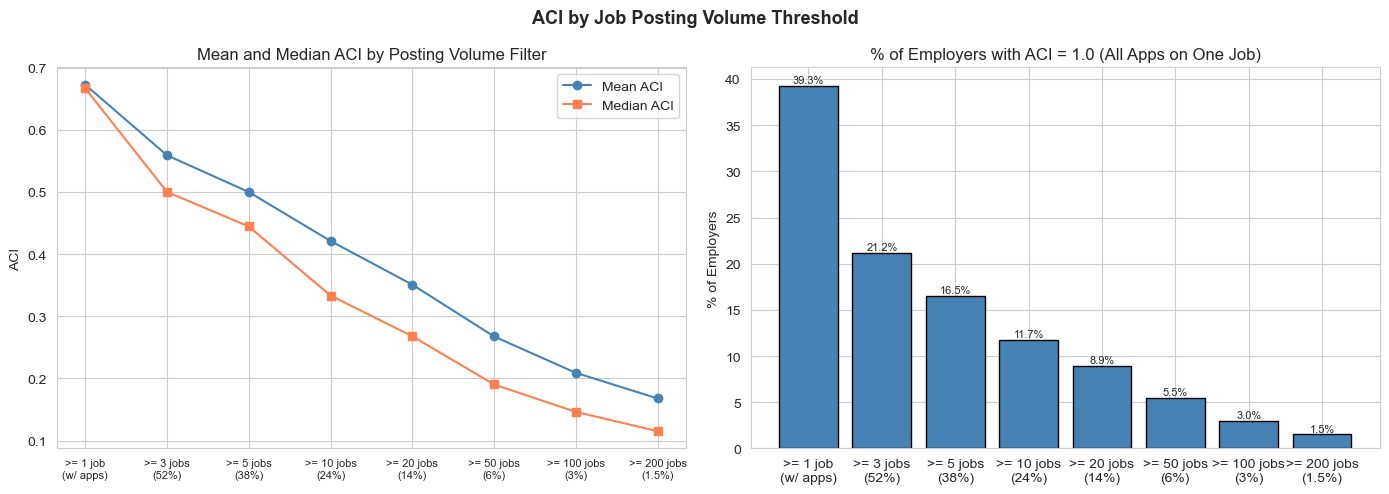

In [42]:
# ACI by posting volume threshold
jobs_aci_full = ep_joined.dropna(subset=['jobs_id'])\
    .drop_duplicates(subset=['employer_id','jobs_id']).copy()

aci_base = jobs_aci_full.groupby('employer_id').agg(
    max_apps_job=('applications_count','max'),
    total_apps=('applications_count','sum'),
    n_jobs=('jobs_id','count')
).reset_index()
aci_base['ACI'] = np.where(aci_base['total_apps'] > 0,
    aci_base['max_apps_job'] / aci_base['total_apps'], np.nan)

# Thresholds chosen based on employer distribution:
# >= 1 with apps (17,383), >= 3 (16,603), >= 5 (12,139),
# >= 10 (7,552), >= 20 (4,445), >= 50 (2,043)
thresholds = [1, 3, 5, 10, 20, 50, 100, 200]
threshold_labels = [
    '>= 1 job\n(w/ apps)',
    '>= 3 jobs\n(52%)',
    '>= 5 jobs\n(38%)',
    '>= 10 jobs\n(24%)',
    '>= 20 jobs\n(14%)',
    '>= 50 jobs\n(6%)',
    '>= 100 jobs\n(3%)',
    '>= 200 jobs\n(1.5%)'
]

results = []
for thresh, label in zip(thresholds, threshold_labels):
    subset = aci_base[
        (aci_base['n_jobs'] >= thresh) & (aci_base['ACI'].notna())
    ]['ACI']
    results.append({
        'Filter': label.replace('\n', ' '),
        'N Employers': len(subset),
        'Mean ACI': subset.mean(),
        'Median ACI': subset.median(),
        'ACI=1.0 (%)': 100*(subset==1.0).mean(),
        'ACI < 0.5 (%)': 100*(subset < 0.5).mean()
    })

aci_thresh_df = pd.DataFrame(results)
print('ACI Statistics by Minimum Posting Threshold:')
display(aci_thresh_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = range(len(thresholds))
axes[0].plot(x, aci_thresh_df['Mean ACI'], marker='o', label='Mean ACI', color='steelblue')
axes[0].plot(x, aci_thresh_df['Median ACI'], marker='s', label='Median ACI', color='coral')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(threshold_labels, fontsize=8)
axes[0].set_ylabel('ACI')
axes[0].set_title('Mean and Median ACI by Posting Volume Filter')
axes[0].legend()

axes[1].bar(threshold_labels, aci_thresh_df['ACI=1.0 (%)'],
            color='steelblue', edgecolor='black')
axes[1].set_ylabel('% of Employers')
axes[1].set_title('% of Employers with ACI = 1.0 (All Apps on One Job)')
for i, v in enumerate(aci_thresh_df['ACI=1.0 (%)']):
    axes[1].text(i, v+0.3, f'{v:.1f}%', ha='center', fontsize=8)

plt.suptitle('ACI by Job Posting Volume Threshold', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. ACI by Employer Characteristics
Examines how Application Concentration Index varies across employer type, size band, EEB segment, and consistency level.

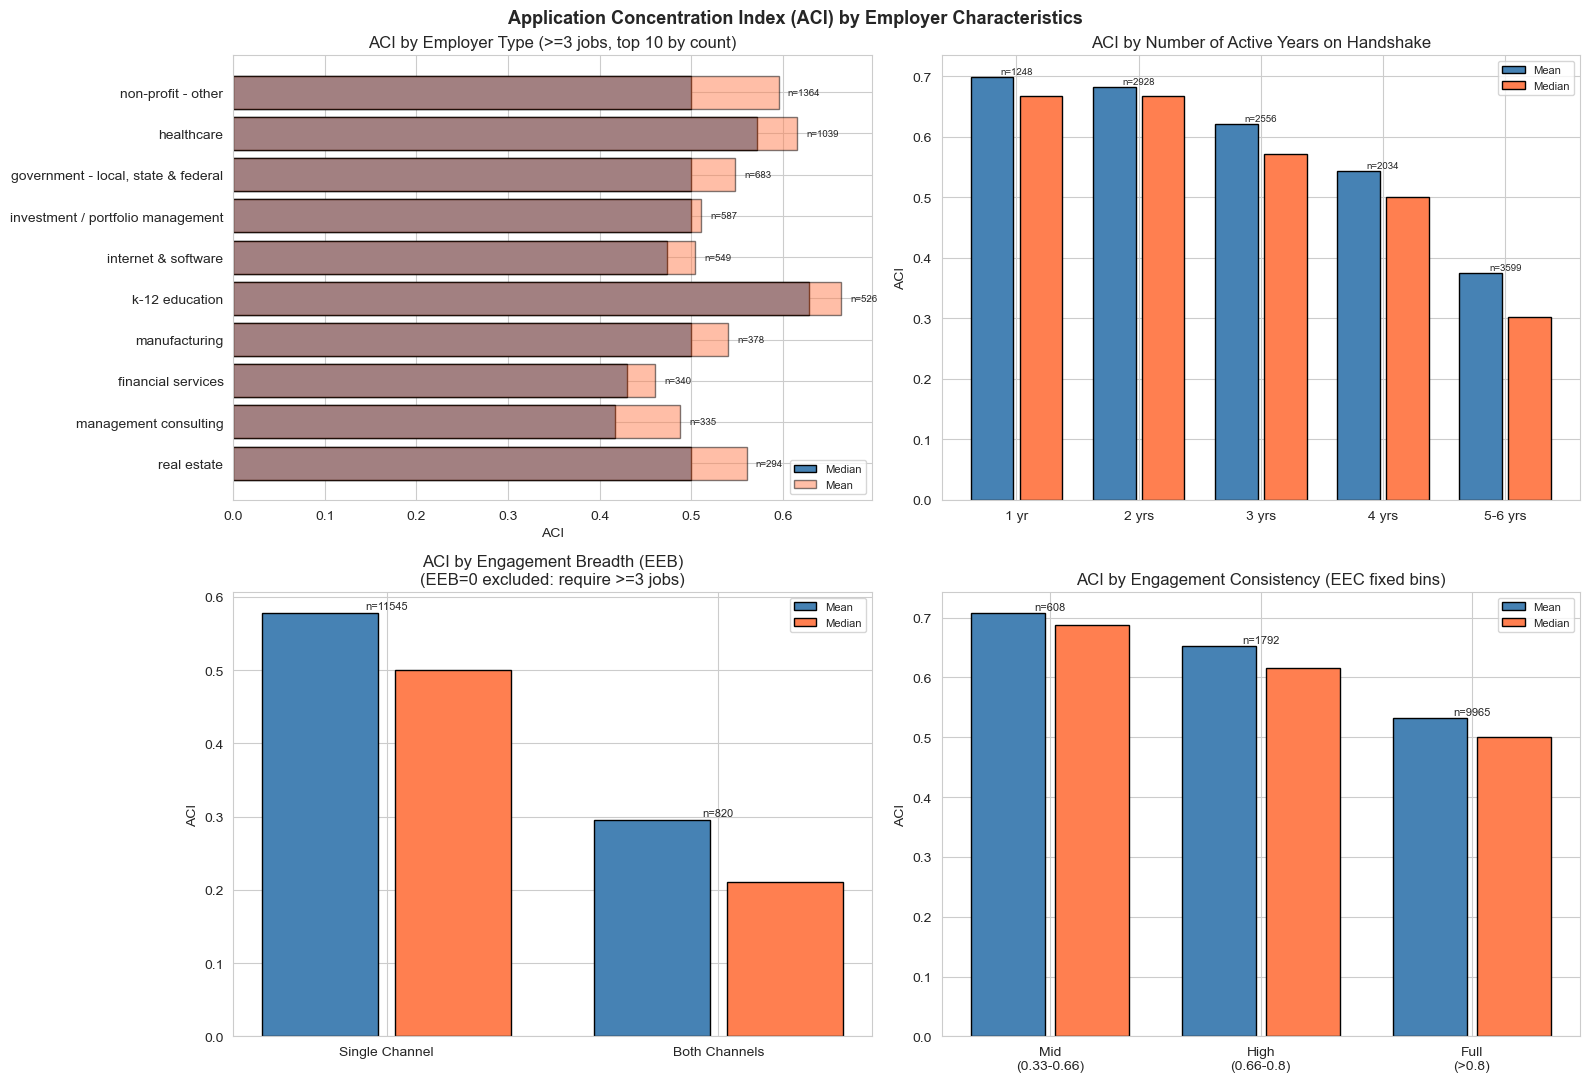

In [43]:
# ACI merged with employer characteristics
aci_enriched = aci_base.merge(
    employer_inf.reset_index()[['employer_id', 'employer_type', 'employer_size_mid', 'EEB', 'EEC']],
    on='employer_id', how='left'
)
aci_enriched = aci_enriched[aci_enriched['ACI'].notna() & (aci_enriched['n_jobs'] >= 3)]

# Size band — use size_min directly from ep_base instead of size_mid
# since size_mid is null when both min and max are null
size_lookup = ep_joined.dropna(subset=['employer_id'])\
    .groupby('employer_id')[['employer_size_min','employer_size_max']].first().reset_index()
aci_enriched = aci_enriched.merge(size_lookup, on='employer_id', how='left')
aci_enriched['size_band'] = pd.cut(
    aci_enriched['employer_size_min'].fillna(0),
    bins=[0, 50, 250, 1000, 5000, float('inf')],
    labels=['Micro (<50)', 'Small (50-250)', 'Mid (250-1k)', 'Large (1k-5k)', 'Enterprise (5k+)']
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. ACI by employer type — sort by count, show top 10 most common sectors
type_aci = aci_enriched.dropna(subset=['employer_type'])\
    .groupby('employer_type')['ACI'].agg(['mean','median','count'])\
    .reset_index().query('count >= 10')\
    .sort_values('count', ascending=False).head(10)  # changed: sort by count not median
axes[0,0].barh(type_aci['employer_type'][::-1], type_aci['median'][::-1],
               color='steelblue', edgecolor='black', label='Median')
axes[0,0].barh(type_aci['employer_type'][::-1], type_aci['mean'][::-1],
               color='coral', edgecolor='black', alpha=0.5, label='Mean')
for i, (_, row) in enumerate(type_aci[::-1].iterrows()):
    axes[0,0].text(max(row['mean'], row['median']) + 0.01, i,
                   f"n={int(row['count'])}", va='center', fontsize=7)
axes[0,0].set_xlabel('ACI')
axes[0,0].set_title('ACI by Employer Type (>=3 jobs, top 10 by count)')
axes[0,0].legend(fontsize=8)

# 2. ACI by active years band (replaces size band — size data too sparse)
aci_enriched2 = aci_enriched.merge(
    employer_inf.reset_index()[['employer_id', 'active_years_unified', 'years_span']],
    on='employer_id', how='left'
)

aci_enriched2['active_years_band'] = pd.cut(
    aci_enriched2['active_years_unified'].fillna(0),
    bins=[0, 1, 2, 3, 4, 7],
    labels=['1 yr', '2 yrs', '3 yrs', '4 yrs', '5-6 yrs'],
    include_lowest=True
)

years_aci = aci_enriched2.dropna(subset=['active_years_band'])\
    .groupby('active_years_band', observed=True)['ACI']\
    .agg(['mean', 'median', 'count']).reset_index()

x2 = range(len(years_aci))
axes[0,1].bar([i-0.2 for i in x2], years_aci['mean'], 0.35,
              label='Mean', color='steelblue', edgecolor='black')
axes[0,1].bar([i+0.2 for i in x2], years_aci['median'], 0.35,
              label='Median', color='coral', edgecolor='black')
axes[0,1].set_xticks(list(x2))
axes[0,1].set_xticklabels(years_aci['active_years_band'])
axes[0,1].set_ylabel('ACI')
axes[0,1].set_title('ACI by Number of Active Years on Handshake')
axes[0,1].legend(fontsize=8)
for i, (_, row) in enumerate(years_aci.iterrows()):
    axes[0,1].text(i, max(row['mean'], row['median']) + 0.005,
                   f"n={int(row['count'])}", ha='center', fontsize=7)

# 3. ACI by EEB (note: EEB=0 excluded by n_jobs>=3 filter)
eeb_aci = aci_enriched.dropna(subset=['EEB'])\
    .groupby('EEB')['ACI'].agg(['mean','median','count']).reset_index()
eeb_labels = {1: 'Single Channel', 2: 'Both Channels'}
eeb_aci['label'] = eeb_aci['EEB'].map(eeb_labels)
eeb_aci = eeb_aci.dropna(subset=['label'])
axes[1,0].bar([i-0.2 for i in range(len(eeb_aci))], eeb_aci['mean'], 0.35,
              label='Mean', color='steelblue', edgecolor='black')
axes[1,0].bar([i+0.2 for i in range(len(eeb_aci))], eeb_aci['median'], 0.35,
              label='Median', color='coral', edgecolor='black')
axes[1,0].set_xticks(range(len(eeb_aci)))
axes[1,0].set_xticklabels(eeb_aci['label'])
axes[1,0].set_ylabel('ACI')
axes[1,0].set_title('ACI by Engagement Breadth (EEB)\n(EEB=0 excluded: require >=3 jobs)')
axes[1,0].legend(fontsize=8)
for i, (_, row) in enumerate(eeb_aci.iterrows()):
    axes[1,0].text(i, max(row['mean'], row['median']) + 0.005,
                   f"n={int(row['count'])}", ha='center', fontsize=8)

# 4. ACI by EEC — replace quartile with fixed meaningful bins
aci_enriched['EEC_bin'] = pd.cut(
    aci_enriched['EEC'].fillna(0),
    bins=[0, 0.33, 0.66, 0.8, 1.01],
    labels=['Low\n(0-0.33)', 'Mid\n(0.33-0.66)', 'High\n(0.66-0.8)', 'Full\n(>0.8)'],
    include_lowest=True
)
eec_aci = aci_enriched.dropna(subset=['EEC_bin'])\
    .groupby('EEC_bin', observed=True)['ACI'].agg(['mean','median','count']).reset_index()
axes[1,1].bar([i-0.2 for i in range(len(eec_aci))], eec_aci['mean'], 0.35,
              label='Mean', color='steelblue', edgecolor='black')
axes[1,1].bar([i+0.2 for i in range(len(eec_aci))], eec_aci['median'], 0.35,
              label='Median', color='coral', edgecolor='black')
axes[1,1].set_xticks(range(len(eec_aci)))
axes[1,1].set_xticklabels(eec_aci['EEC_bin'])
axes[1,1].set_ylabel('ACI')
axes[1,1].set_title('ACI by Engagement Consistency (EEC fixed bins)')
axes[1,1].legend(fontsize=8)
for i, (_, row) in enumerate(eec_aci.iterrows()):
    axes[1,1].text(i, max(row['mean'], row['median']) + 0.005,
                   f"n={int(row['count'])}", ha='center', fontsize=8)

plt.suptitle('Application Concentration Index (ACI) by Employer Characteristics',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. EEIS with PCA-Derived Weights (Mathematically Defensible Alternative)
The existing EEIS uses equal weights (0.25 each). This section derives weights using **Principal Component Analysis (PCA)**: the weight of each channel equals its loading on the first principal component, which captures the direction of maximum variance. This is mathematically defensible because it lets the data determine how much each channel contributes to overall engagement variation rather than assuming they contribute equally.

The existing equal-weight EEIS is preserved. The PCA version is added as `EEIS_pca`.

Channel Weights Across Methods:
Channel            Equal      PCA
---------------------------------
Jobs              0.2500   0.1290
Events            0.2500   0.2758
Applications      0.2500   0.2892
Attendees         0.2500   0.3060

PCA PC1 variance explained: 55.6%

Top 15 Employers: Rankings Across Three EEIS Methods
(EEIS_rank = percentile score: % of employers outranked across all channels)


,employer_name,EEIS_equal,rank_equal,EEIS_pca,rank_pca,rank_shift_eq_pca,EEIS_rank,rank_based
0,ey,0.56,1.0,0.65,1.0,0.0,99.90,9.0
1,jpmorganchase,0.44,2.0,0.49,3.0,1.0,99.97,1.0
2,amazon,0.43,3.0,0.49,4.0,1.0,99.95,2.0
3,pwc,0.43,4.0,0.50,2.0,2.0,99.80,25.0
4,morgan stanley,0.41,5.0,0.46,7.0,2.0,99.92,4.0
5,mckinsey & company,0.40,6.0,0.46,5.0,1.0,99.75,39.0
6,goldman sachs,0.40,7.0,0.46,6.0,1.0,99.72,49.0
7,kpmg llp,0.37,8.0,0.43,8.0,0.0,99.66,61.0
8,capital one,0.33,9.0,0.38,9.0,0.0,98.29,687.0
9,deloitte,0.32,10.0,0.37,10.0,0.0,99.78,29.0


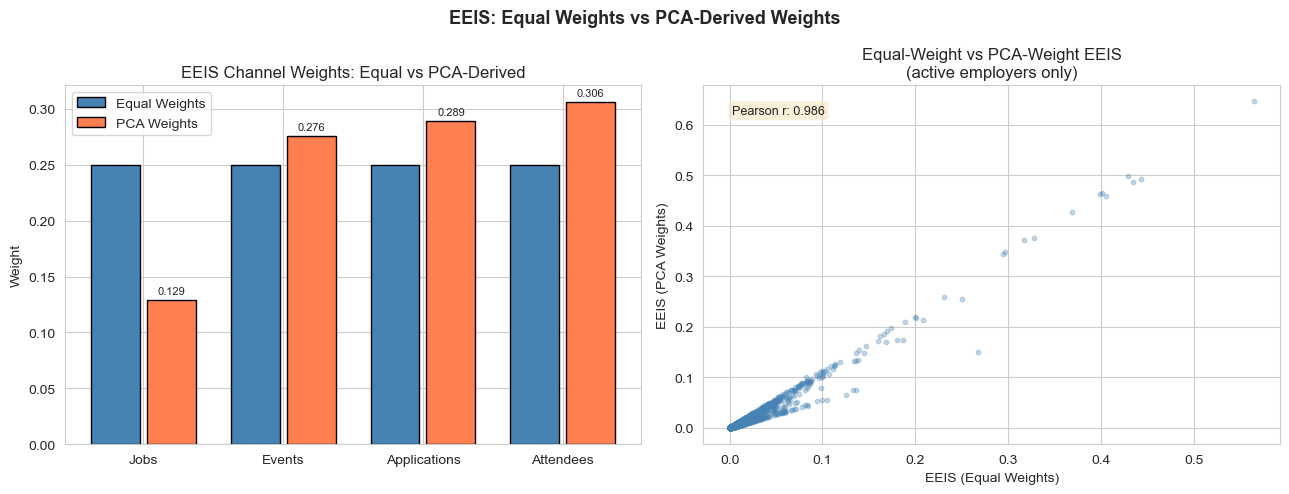

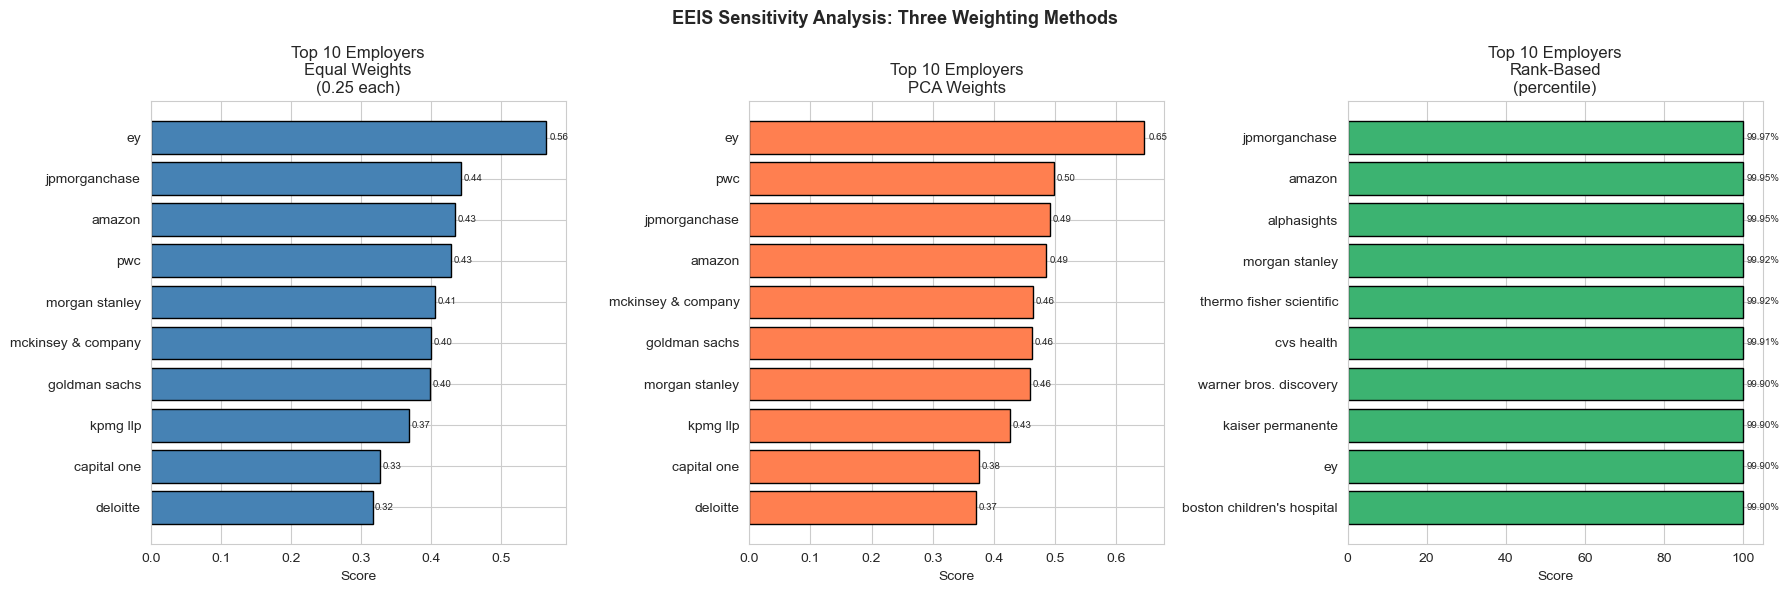


Spearman Rank Correlation Between Methods (active employers):
  Equal vs PCA:        0.9952
  Equal vs Rank-Based: 0.9805
  PCA vs Rank-Based:   0.9674

Interpretation: correlations > 0.90 indicate methods agree on rankings.
Lower correlations flag employers whose position is sensitive to method choice.


In [44]:
# EEIS Sensitivity Analysis: Equal Weights, PCA, and Rank-Based
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

eeis_cols = ['total_jobs', 'total_events_dedup', 'total_applications', 'total_attendees_dedup']
eeis_input = employer_inf[eeis_cols].fillna(0)

# Min-max normalize (shared base for equal and PCA versions)
scaler = MinMaxScaler()
normed = scaler.fit_transform(eeis_input)

# ── 1. Equal Weights ─────────────────────────────────────────────
w_equal = np.array([0.25, 0.25, 0.25, 0.25])
employer_inf['EEIS_equal'] = normed @ w_equal

# ── 2. PCA Weights ───────────────────────────────────────────────
pca = PCA(n_components=4)
pca.fit(normed)
pc1_loadings = np.abs(pca.components_[0])
w_pca = pc1_loadings / pc1_loadings.sum()
employer_inf['EEIS_pca'] = normed @ w_pca

# ── 3. Rank-Based (percentile score) ─────────────────────────────
for col in eeis_cols:
    employer_inf[f'rank_{col}'] = employer_inf[col].fillna(0)\
        .rank(ascending=True, method='average')

def active_rank_mean(row):
    ranks = []
    for col in eeis_cols:
        val = row[col] if not pd.isna(row[col]) else 0
        if val > 0:
            ranks.append(row[f'rank_{col}'])
    return np.mean(ranks) if ranks else 0

# Drop stale columns to prevent interference on re-run
employer_inf = employer_inf.drop(
    columns=['EEIS_rank', 'rank_based'], errors='ignore'
)
employer_inf['EEIS_rank'] = employer_inf.apply(active_rank_mean, axis=1)

# Express as percentile: % of employers this employer outranks
total = len(employer_inf)
employer_inf['EEIS_rank'] = employer_inf['EEIS_rank'] / total * 100

# ── Compute final rankings ────────────────────────────────────────
employer_inf['rank_equal']        = employer_inf['EEIS_equal'].rank(ascending=False, method='min')
employer_inf['rank_pca']          = employer_inf['EEIS_pca'].rank(ascending=False, method='min')
employer_inf['rank_based']        = employer_inf['EEIS_rank'].rank(ascending=False, method='min')
employer_inf['rank_shift_eq_pca'] = (employer_inf['rank_pca'] - employer_inf['rank_equal']).abs()

# ── Weight comparison table ───────────────────────────────────────
channel_names = ['Jobs', 'Events', 'Applications', 'Attendees']
print('Channel Weights Across Methods:')
print(f"{'Channel':<15} {'Equal':>8} {'PCA':>8}")
print('-' * 33)
for name, we, wp in zip(channel_names, w_equal, w_pca):
    print(f"{name:<15} {we:>8.4f} {wp:>8.4f}")
print(f"\nPCA PC1 variance explained: {pca.explained_variance_ratio_[0]:.1%}")

# ── Top 15 comparison table ───────────────────────────────────────
top15 = employer_inf.sort_values('EEIS_equal', ascending=False).head(15)[
    ['employer_name',
     'EEIS_equal', 'rank_equal',
     'EEIS_pca',   'rank_pca',   'rank_shift_eq_pca',
     'EEIS_rank',  'rank_based']
].reset_index(drop=True)

print('\nTop 15 Employers: Rankings Across Three EEIS Methods')
print('(EEIS_rank = percentile score: % of employers outranked across all channels)')
display(top15.round(2))

# ── Weight comparison visualization ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(4)
axes[0].bar(x - 0.2, w_equal, 0.35, label='Equal Weights', color='steelblue', edgecolor='black')
axes[0].bar(x + 0.2, w_pca,   0.35, label='PCA Weights',   color='coral',     edgecolor='black')
axes[0].set_xticks(x)
axes[0].set_xticklabels(channel_names)
axes[0].set_ylabel('Weight')
axes[0].set_title('EEIS Channel Weights: Equal vs PCA-Derived')
axes[0].legend()
for i, (we, wp) in enumerate(zip(w_equal, w_pca)):
    axes[0].text(i + 0.2, wp + 0.005, f'{wp:.3f}', ha='center', fontsize=8)

# Equal vs PCA scatter
active = employer_inf[
    (employer_inf['total_jobs'] > 0) |
    (employer_inf['total_events_dedup'].fillna(0) > 0)
]
axes[1].scatter(active['EEIS_equal'], active['EEIS_pca'],
                alpha=0.3, s=10, color='steelblue')
axes[1].set_xlabel('EEIS (Equal Weights)')
axes[1].set_ylabel('EEIS (PCA Weights)')
axes[1].set_title('Equal-Weight vs PCA-Weight EEIS\n(active employers only)')
corr = active[['EEIS_equal', 'EEIS_pca']].corr().iloc[0, 1]
axes[1].text(0.05, 0.92, f'Pearson r: {corr:.3f}',
             transform=axes[1].transAxes, fontsize=9,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('EEIS: Equal Weights vs PCA-Derived Weights', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Top 10 bar charts for all three methods ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

methods = [
    ('EEIS_equal', 'rank_equal', 'Equal Weights\n(0.25 each)', 'steelblue'),
    ('EEIS_pca',   'rank_pca',   'PCA Weights',                'coral'),
    ('EEIS_rank',  'rank_based', 'Rank-Based\n(percentile)',   'mediumseagreen'),
]

for ax, (score_col, rank_col, label, color) in zip(axes, methods):
    top10 = employer_inf.sort_values(rank_col, ascending=True).head(10)
    ax.barh(top10['employer_name'][::-1], top10[score_col][::-1],
            color=color, edgecolor='black')
    ax.set_xlabel('Score')
    ax.set_title(f'Top 10 Employers\n{label}')
    for i, (_, row) in enumerate(top10[::-1].iterrows()):
        suffix = '%' if score_col == 'EEIS_rank' else ''
        ax.text(row[score_col] + row[score_col] * 0.01, i,
                f"{row[score_col]:.2f}{suffix}", va='center', fontsize=7)

plt.suptitle('EEIS Sensitivity Analysis: Three Weighting Methods',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Spearman rank correlations ────────────────────────────────────
active2 = active.dropna(subset=['EEIS_equal', 'EEIS_pca', 'EEIS_rank'])
r_eq_pca,   _ = spearmanr(active2['rank_equal'], active2['rank_pca'])
r_eq_rank,  _ = spearmanr(active2['rank_equal'], active2['rank_based'])
r_pca_rank, _ = spearmanr(active2['rank_pca'],   active2['rank_based'])

print('\nSpearman Rank Correlation Between Methods (active employers):')
print(f"  Equal vs PCA:        {r_eq_pca:.4f}")
print(f"  Equal vs Rank-Based: {r_eq_rank:.4f}")
print(f"  PCA vs Rank-Based:   {r_pca_rank:.4f}")
print('\nInterpretation: correlations > 0.90 indicate methods agree on rankings.')
print('Lower correlations flag employers whose position is sensitive to method choice.')

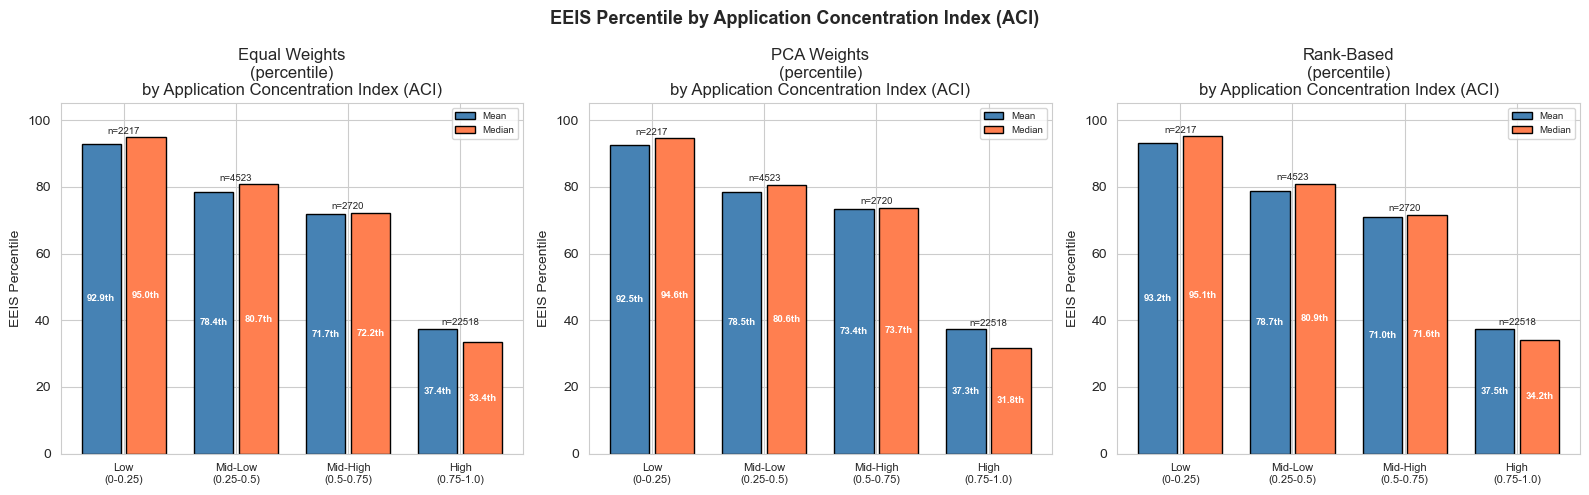

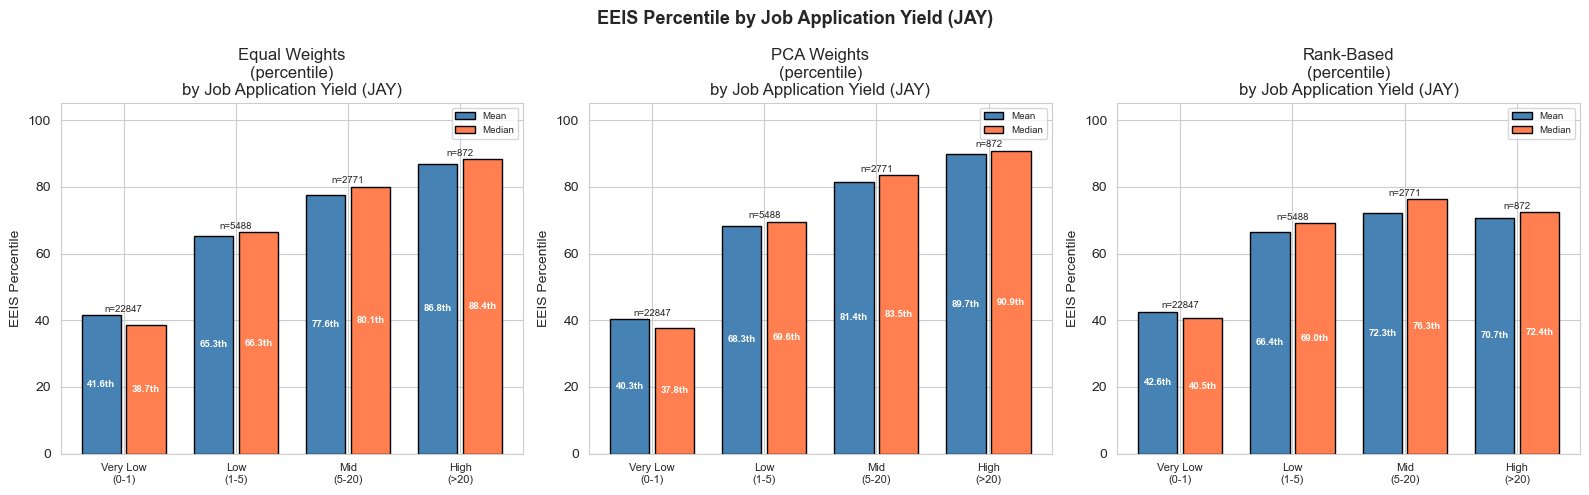

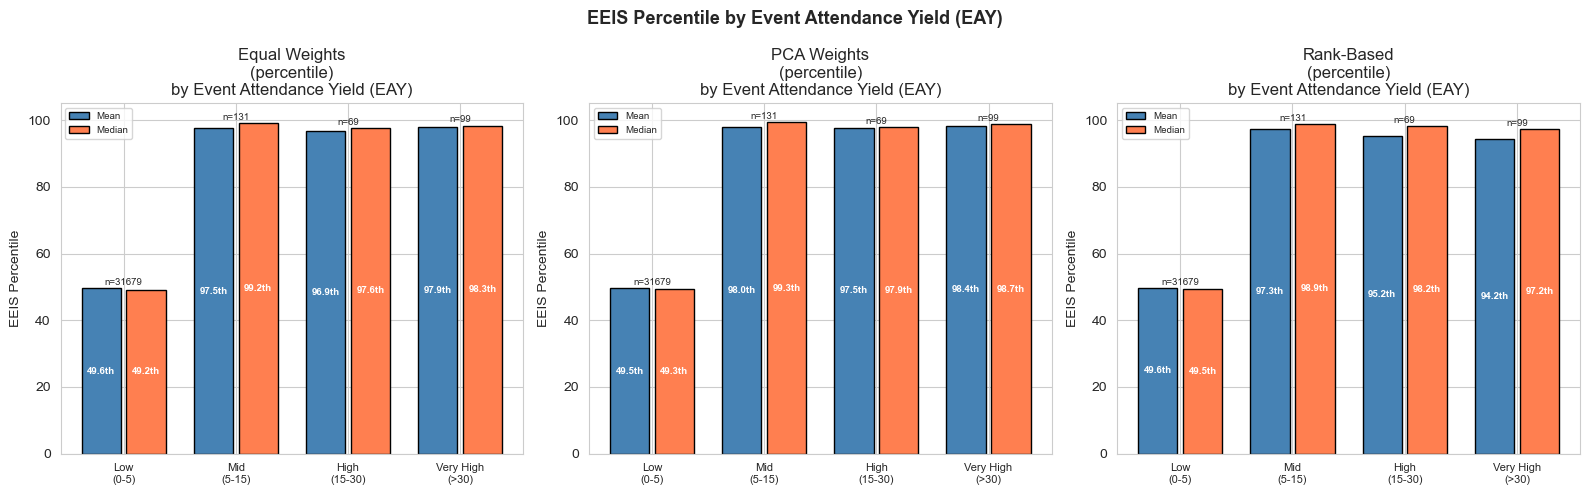

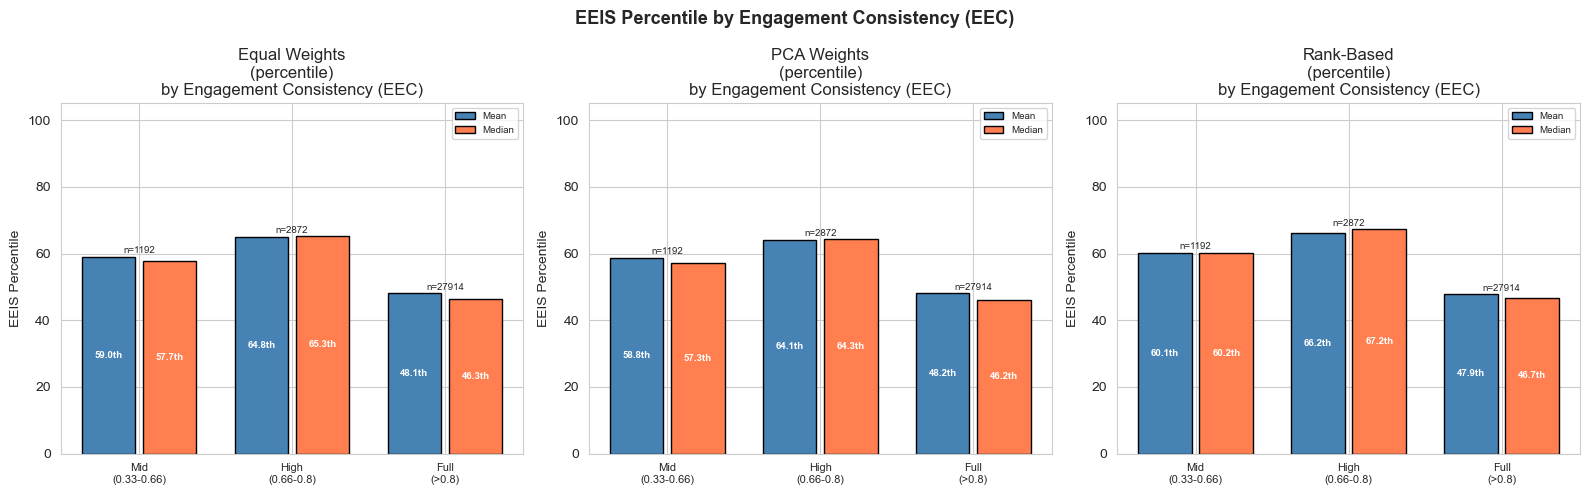

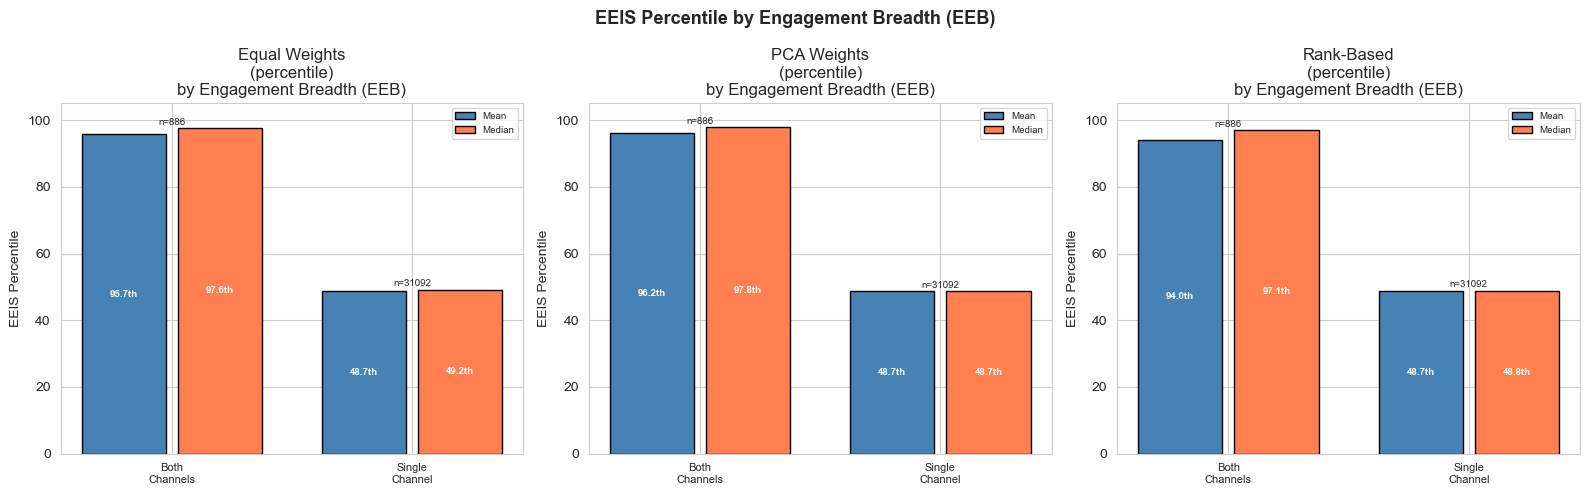

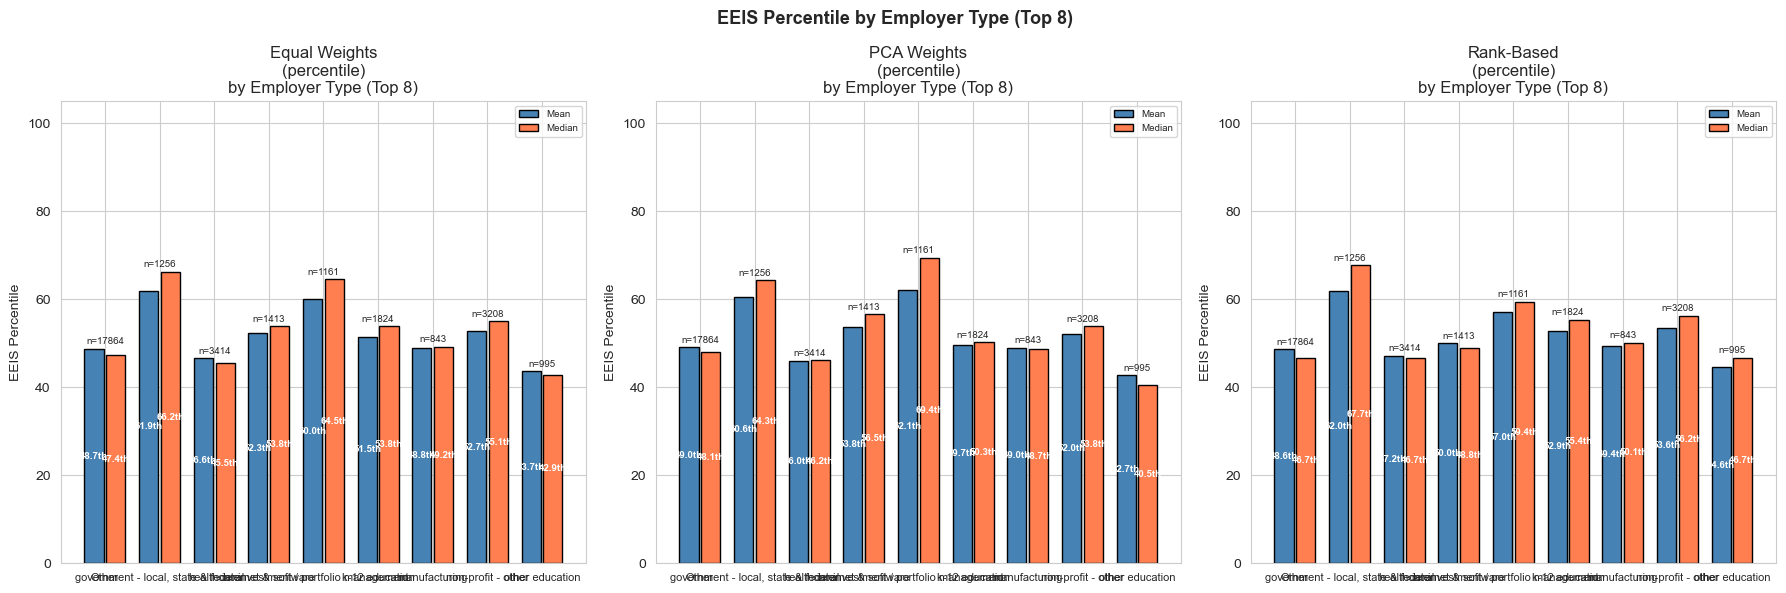


Summary: Median EEIS Percentile by Segment (Equal Weights)

ACI:
  Low
(0-0.25)              median = 95.0th pct  mean = 92.9th pct  (n=2,217)
  Mid-Low
(0.25-0.5)        median = 80.7th pct  mean = 78.4th pct  (n=4,523)
  Mid-High
(0.5-0.75)       median = 72.2th pct  mean = 71.7th pct  (n=2,720)
  High
(0.75-1.0)           median = 33.4th pct  mean = 37.4th pct  (n=22,518)

JAY:
  Very Low
(0-1)            median = 38.7th pct  mean = 41.6th pct  (n=22,847)
  Low
(1-5)                 median = 66.3th pct  mean = 65.3th pct  (n=5,488)
  Mid
(5-20)                median = 80.1th pct  mean = 77.6th pct  (n=2,771)
  High
(>20)                median = 88.4th pct  mean = 86.8th pct  (n=872)

EAY:
  Low
(0-5)                 median = 49.2th pct  mean = 49.6th pct  (n=31,679)
  Mid
(5-15)                median = 99.2th pct  mean = 97.5th pct  (n=131)
  High
(15-30)              median = 97.6th pct  mean = 96.9th pct  (n=69)
  Very High
(>30)           median = 98.3th pct  mean = 97.9th pct  

In [45]:
# EEIS Cross-KPI Segmentation Analysis
# Examines how EEIS_equal, EEIS_pca, and EEIS_rank vary across
# segments defined by other KPI values

eeis_versions = ['EEIS_equal', 'EEIS_pca', 'EEIS_rank']
active_seg = employer_inf[
    (employer_inf['total_jobs'] > 0) |
    (employer_inf['total_events_dedup'].fillna(0) > 0)
].copy()

# Percentile versions of all three EEIS methods
active_seg['EEIS_equal_pct'] = active_seg['EEIS_equal'].rank(pct=True) * 100
active_seg['EEIS_pca_pct']   = active_seg['EEIS_pca'].rank(pct=True) * 100
active_seg['EEIS_rank_pct']  = active_seg['EEIS_rank'].rank(pct=True) * 100

eeis_pct_versions = ['EEIS_equal_pct', 'EEIS_pca_pct', 'EEIS_rank_pct']
eeis_pct_labels   = ['Equal Weights\n(percentile)', 'PCA Weights\n(percentile)', 'Rank-Based\n(percentile)']

# ── Define segments ───────────────────────────────────────────────

# ACI bins
active_seg['ACI_bin'] = pd.cut(
    active_seg['ACI'].fillna(1.0),
    bins=[0, 0.25, 0.5, 0.75, 1.01],
    labels=['Low\n(0-0.25)', 'Mid-Low\n(0.25-0.5)',
            'Mid-High\n(0.5-0.75)', 'High\n(0.75-1.0)'],
    include_lowest=True
)

# JAY bins
active_seg['JAY_bin'] = pd.cut(
    active_seg['JAY'].fillna(0),
    bins=[0, 1, 5, 20, float('inf')],
    labels=['Very Low\n(0-1)', 'Low\n(1-5)',
            'Mid\n(5-20)', 'High\n(>20)'],
    include_lowest=True
)

# EAY bins
active_seg['EAY_bin'] = pd.cut(
    active_seg['EAY'].fillna(0),
    bins=[0, 5, 15, 30, float('inf')],
    labels=['Low\n(0-5)', 'Mid\n(5-15)',
            'High\n(15-30)', 'Very High\n(>30)'],
    include_lowest=True
)

# EEC fixed bins
active_seg['EEC_bin'] = pd.cut(
    active_seg['EEC'].fillna(0),
    bins=[0, 0.33, 0.66, 0.8, 1.01],
    labels=['Low\n(0-0.33)', 'Mid\n(0.33-0.66)',
            'High\n(0.66-0.8)', 'Full\n(>0.8)'],
    include_lowest=True
)

# EEB segment
eeb_map = {1: 'Single\nChannel', 2: 'Both\nChannels'}
active_seg['EEB_label'] = active_seg['EEB'].map(eeb_map)

# Employer type — top 8 by count
top8_types = active_seg['employer_type'].value_counts().head(8).index
active_seg['type_group'] = active_seg['employer_type'].where(
    active_seg['employer_type'].isin(top8_types), 'Other'
)

# ── Plotting function (percentile) ───────────────────────────────
def plot_eeis_by_segment(seg_col, seg_label, figsize=(16, 5)):
    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=False)
    for ax, pct_col, pct_label in zip(axes, eeis_pct_versions, eeis_pct_labels):
        grp = active_seg.dropna(subset=[seg_col, pct_col])\
            .groupby(seg_col, observed=True)[pct_col]\
            .agg(['mean', 'median', 'count']).reset_index()

        x = range(len(grp))
        bars_mean   = ax.bar([i-0.2 for i in x], grp['mean'],   0.35,
                             label='Mean',   color='steelblue', edgecolor='black')
        bars_median = ax.bar([i+0.2 for i in x], grp['median'], 0.35,
                             label='Median', color='coral',     edgecolor='black')

        # Label inside each bar with its percentile value
        for bar in bars_mean:
            h = bar.get_height()
            if h > 3:  # only label if bar tall enough to fit text
                ax.text(bar.get_x() + bar.get_width()/2, h/2,
                        f'{h:.1f}th', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')

        for bar in bars_median:
            h = bar.get_height()
            if h > 3:
                ax.text(bar.get_x() + bar.get_width()/2, h/2,
                        f'{h:.1f}th', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')

        ax.set_xticks(list(x))
        ax.set_xticklabels(grp[seg_col], fontsize=8)
        ax.set_ylabel('EEIS Percentile')
        ax.set_ylim(0, 105)
        ax.set_title(f'{pct_label}\nby {seg_label}')
        ax.legend(fontsize=7)

        # n= labels above bars
        for i, (_, row) in enumerate(grp.iterrows()):
            ax.text(i, max(row['mean'], row['median']) + 1,
                    f"n={int(row['count'])}", ha='center', fontsize=7)

    plt.suptitle(f'EEIS Percentile by {seg_label}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ── Run all segmentations ─────────────────────────────────────────
plot_eeis_by_segment('ACI_bin',    'Application Concentration Index (ACI)')
plot_eeis_by_segment('JAY_bin',    'Job Application Yield (JAY)')
plot_eeis_by_segment('EAY_bin',    'Event Attendance Yield (EAY)')
plot_eeis_by_segment('EEC_bin',    'Engagement Consistency (EEC)')
plot_eeis_by_segment('EEB_label',  'Engagement Breadth (EEB)')
plot_eeis_by_segment('type_group', 'Employer Type (Top 8)', figsize=(18, 6))

# ── Summary table: median EEIS percentile by segment ─────────────
print('\nSummary: Median EEIS Percentile by Segment (Equal Weights)')
print('=' * 60)

segments = {
    'ACI':  'ACI_bin',
    'JAY':  'JAY_bin',
    'EAY':  'EAY_bin',
    'EEC':  'EEC_bin',
    'EEB':  'EEB_label',
}

for kpi, col in segments.items():
    grp = active_seg.dropna(subset=[col])\
        .groupby(col, observed=True)['EEIS_equal_pct']\
        .agg(['mean', 'median', 'count']).reset_index()
    print(f'\n{kpi}:')
    for _, row in grp.iterrows():
        print(f"  {str(row[col]):<25} median = {row['median']:.1f}th pct  "
              f"mean = {row['mean']:.1f}th pct  (n={int(row['count']):,})")

## 4. JAY Segmented by Employer Characteristics
Job Application Yield across employer type, size band, EEB segment, and consistency quartile.

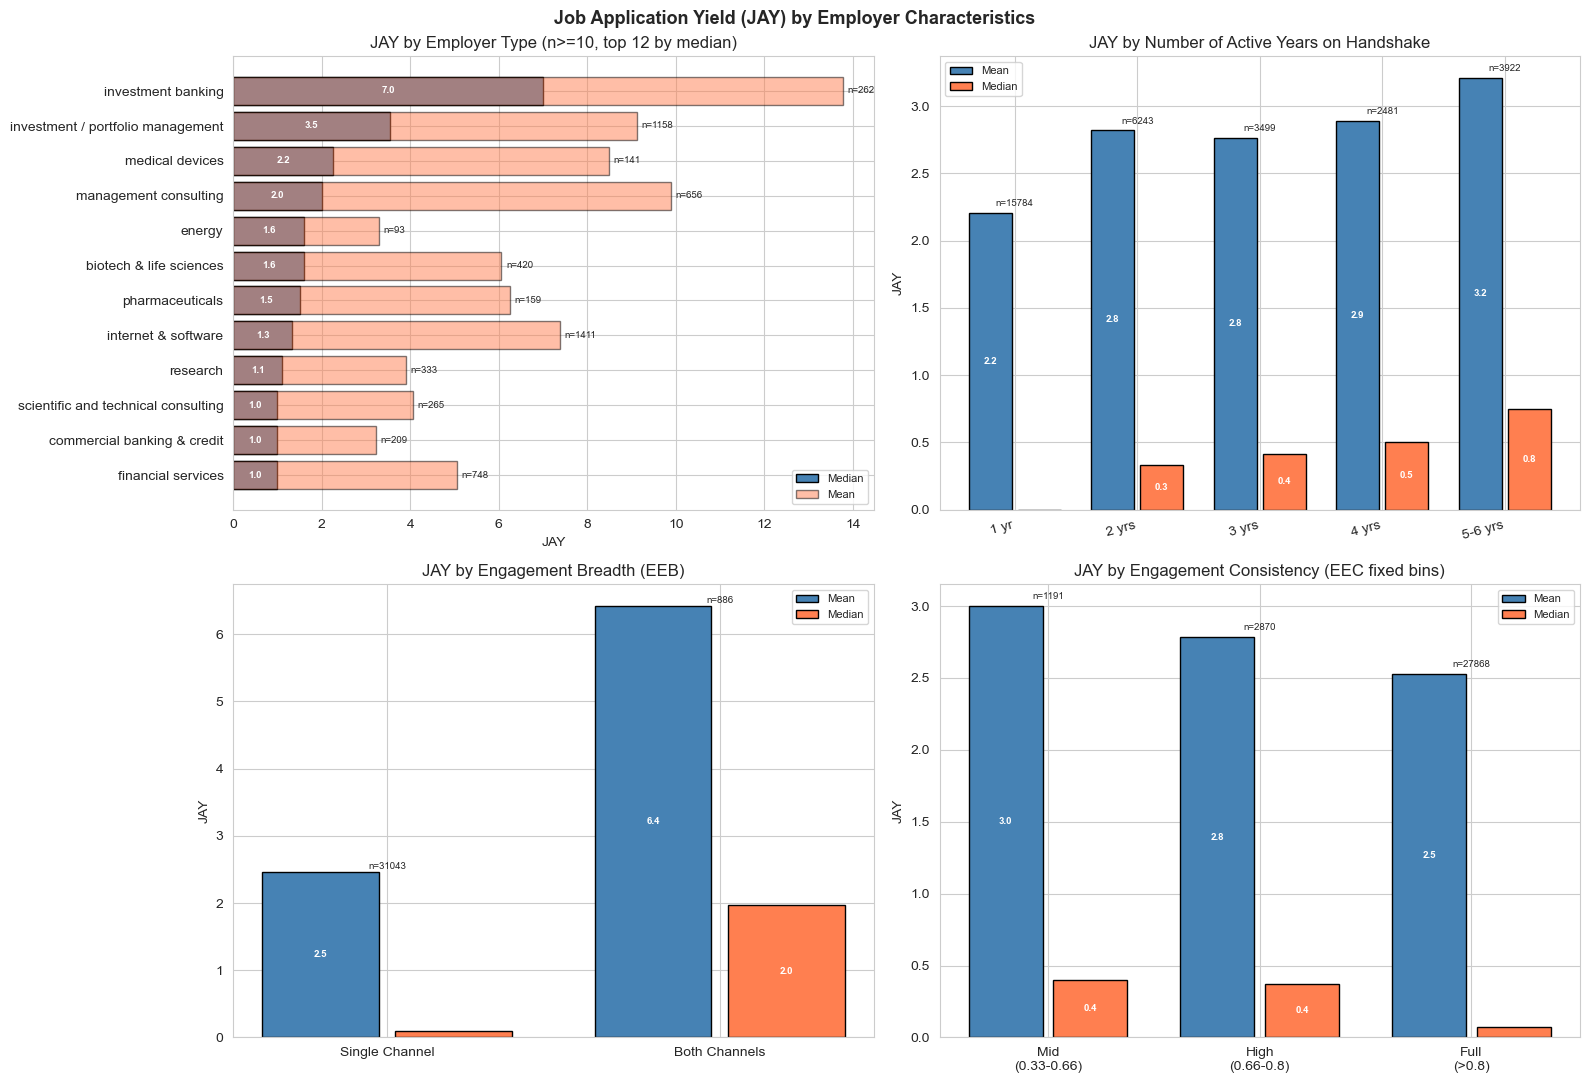

In [46]:
jay_data = employer_inf[employer_inf['total_jobs'] > 0].copy()

# EEC fixed bins
jay_data['EEC_bin'] = pd.cut(
    jay_data['EEC'].fillna(0),
    bins=[0, 0.33, 0.66, 0.8, 1.01],
    labels=['Low\n(0-0.33)', 'Mid\n(0.33-0.66)', 'High\n(0.66-0.8)', 'Full\n(>0.8)'],
    include_lowest=True
)

# Active years band
jay_data['active_years_band'] = pd.cut(
    jay_data['active_years_unified'].fillna(0),
    bins=[0, 1, 2, 3, 4, 7],
    labels=['1 yr', '2 yrs', '3 yrs', '4 yrs', '5-6 yrs'],
    include_lowest=True
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. JAY by employer type (horizontal bars)
type_jay = jay_data.dropna(subset=['employer_type'])\
    .groupby('employer_type')['JAY'].agg(['mean', 'median', 'count'])\
    .reset_index().query('count >= 10')\
    .sort_values('median', ascending=False).head(12)

bars_med  = axes[0,0].barh(type_jay['employer_type'][::-1], type_jay['median'][::-1],
                            color='steelblue', edgecolor='black', label='Median')
bars_mean = axes[0,0].barh(type_jay['employer_type'][::-1], type_jay['mean'][::-1],
                            color='coral', edgecolor='black', alpha=0.5, label='Mean')

for bar, val in zip(bars_med, type_jay['median'][::-1]):
    if bar.get_width() > 0.5:
        axes[0,0].text(bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')

for bar, (_, row) in zip(bars_med, type_jay[::-1].iterrows()):
    axes[0,0].text(max(row['mean'], row['median']) + 0.1,
                   bar.get_y() + bar.get_height()/2,
                   f"n={int(row['count'])}", va='center', fontsize=7)

axes[0,0].set_xlabel('JAY')
axes[0,0].set_title('JAY by Employer Type (n>=10, top 12 by median)')
axes[0,0].legend(fontsize=8)

# 2. JAY by active years band
years_jay = jay_data.dropna(subset=['active_years_band'])\
    .groupby('active_years_band', observed=True)['JAY']\
    .agg(['mean', 'median', 'count']).reset_index()
x2 = range(len(years_jay))

bars_mean2   = axes[0,1].bar([i-0.2 for i in x2], years_jay['mean'], 0.35,
                              label='Mean', color='steelblue', edgecolor='black')
bars_median2 = axes[0,1].bar([i+0.2 for i in x2], years_jay['median'], 0.35,
                              label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean2, years_jay['mean']):
    if bar.get_height() > 0.3:
        axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_median2, years_jay['median']):
    if bar.get_height() > 0.3:
        axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')

axes[0,1].set_xticks(list(x2))
axes[0,1].set_xticklabels(years_jay['active_years_band'], rotation=15, ha='right')
axes[0,1].set_ylabel('JAY')
axes[0,1].set_title('JAY by Number of Active Years on Handshake')
axes[0,1].legend(fontsize=8)
for i, (_, row) in enumerate(years_jay.iterrows()):
    axes[0,1].text(i, max(row['mean'], row['median']) + 0.05,
                   f"n={int(row['count'])}", ha='center', fontsize=7)

# 3. JAY by EEB
eeb_jay = jay_data.groupby('EEB')['JAY']\
    .agg(['mean', 'median', 'count']).reset_index()
eeb_map = {0: 'Inactive', 1: 'Single Channel', 2: 'Both Channels'}
eeb_jay['label'] = eeb_jay['EEB'].map(eeb_map)

bars_mean3   = axes[1,0].bar([i-0.2 for i in range(len(eeb_jay))], eeb_jay['mean'], 0.35,
                              label='Mean', color='steelblue', edgecolor='black')
bars_median3 = axes[1,0].bar([i+0.2 for i in range(len(eeb_jay))], eeb_jay['median'], 0.35,
                              label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean3, eeb_jay['mean']):
    if bar.get_height() > 0.3:
        axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_median3, eeb_jay['median']):
    if bar.get_height() > 0.3:
        axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')

axes[1,0].set_xticks(range(len(eeb_jay)))
axes[1,0].set_xticklabels(eeb_jay['label'])
axes[1,0].set_ylabel('JAY')
axes[1,0].set_title('JAY by Engagement Breadth (EEB)')
axes[1,0].legend(fontsize=8)
for i, (_, row) in enumerate(eeb_jay.iterrows()):
    axes[1,0].text(i, max(row['mean'], row['median']) + 0.05,
                   f"n={int(row['count'])}", ha='center', fontsize=7)

# 4. JAY by EEC fixed bins
eec_jay = jay_data.dropna(subset=['EEC_bin'])\
    .groupby('EEC_bin', observed=True)['JAY']\
    .agg(['mean', 'median', 'count']).reset_index()

bars_mean4   = axes[1,1].bar([i-0.2 for i in range(len(eec_jay))], eec_jay['mean'], 0.35,
                              label='Mean', color='steelblue', edgecolor='black')
bars_median4 = axes[1,1].bar([i+0.2 for i in range(len(eec_jay))], eec_jay['median'], 0.35,
                              label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean4, eec_jay['mean']):
    if bar.get_height() > 0.3:
        axes[1,1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_median4, eec_jay['median']):
    if bar.get_height() > 0.3:
        axes[1,1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                       f'{val:.1f}', ha='center', va='center',
                       fontsize=7, color='white', fontweight='bold')

axes[1,1].set_xticks(range(len(eec_jay)))
axes[1,1].set_xticklabels(eec_jay['EEC_bin'])
axes[1,1].set_ylabel('JAY')
axes[1,1].set_title('JAY by Engagement Consistency (EEC fixed bins)')
axes[1,1].legend(fontsize=8)
for i, (_, row) in enumerate(eec_jay.iterrows()):
    axes[1,1].text(i, max(row['mean'], row['median']) + 0.05,
                   f"n={int(row['count'])}", ha='center', fontsize=7)

plt.suptitle('Job Application Yield (JAY) by Employer Characteristics',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. EAY Segmented by Employer Characteristics
Event Attendance Yield across employer type, size band, event medium mix, and EEB segment.

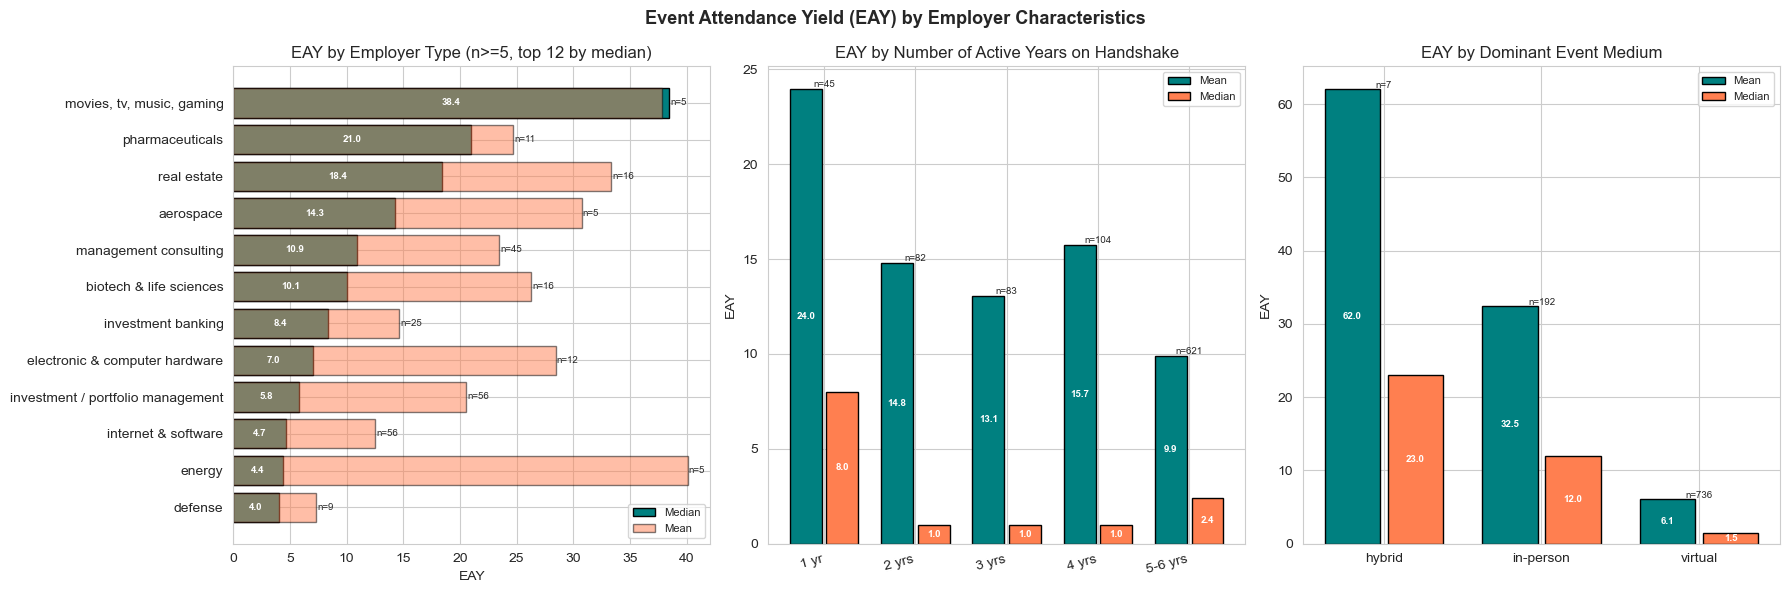

In [47]:
eay_data = employer_inf[employer_inf['total_events_dedup'].fillna(0) > 0].copy()

# Active years band (replaces size band)
eay_data['active_years_band'] = pd.cut(
    eay_data['active_years_unified'].fillna(0),
    bins=[0, 1, 2, 3, 4, 7],
    labels=['1 yr', '2 yrs', '3 yrs', '4 yrs', '5-6 yrs'],
    include_lowest=True
)

# Dominant event medium per employer
medium_per_emp = ep_joined.dropna(subset=['events_id', 'event_medium'])\
    .drop_duplicates(subset=['events_id'])\
    .groupby('employer_id')['event_medium'].agg(lambda x: x.value_counts().index[0])\
    .reset_index().rename(columns={'event_medium': 'dominant_medium'})
eay_data = eay_data.merge(medium_per_emp, on='employer_id', how='left')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. EAY by employer type (horizontal)
type_eay = eay_data.dropna(subset=['employer_type'])\
    .groupby('employer_type')['EAY'].agg(['mean', 'median', 'count'])\
    .reset_index().query('count >= 5')\
    .sort_values('median', ascending=False).head(12)

bars_med  = axes[0].barh(type_eay['employer_type'][::-1], type_eay['median'][::-1],
                          color='teal', edgecolor='black', label='Median')
bars_mean = axes[0].barh(type_eay['employer_type'][::-1], type_eay['mean'][::-1],
                          color='coral', edgecolor='black', alpha=0.5, label='Mean')

for bar, val in zip(bars_med, type_eay['median'][::-1]):
    if bar.get_width() > 0.5:
        axes[0].text(bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

for bar, (_, row) in zip(bars_med, type_eay[::-1].iterrows()):
    axes[0].text(max(row['mean'], row['median']) + 0.1,
                 bar.get_y() + bar.get_height()/2,
                 f"n={int(row['count'])}", va='center', fontsize=7)

axes[0].set_xlabel('EAY')
axes[0].set_title('EAY by Employer Type (n>=5, top 12 by median)')
axes[0].legend(fontsize=8)

# 2. EAY by active years band (replaces size band)
years_eay = eay_data.dropna(subset=['active_years_band'])\
    .groupby('active_years_band', observed=True)['EAY']\
    .agg(['mean', 'median', 'count']).reset_index()
x = range(len(years_eay))

bars_mean2   = axes[1].bar([i-0.2 for i in x], years_eay['mean'], 0.35,
                            label='Mean', color='teal', edgecolor='black')
bars_median2 = axes[1].bar([i+0.2 for i in x], years_eay['median'], 0.35,
                            label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean2, years_eay['mean']):
    if bar.get_height() > 0.3:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_median2, years_eay['median']):
    if bar.get_height() > 0.3:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

axes[1].set_xticks(list(x))
axes[1].set_xticklabels(years_eay['active_years_band'], rotation=15, ha='right')
axes[1].set_ylabel('EAY')
axes[1].set_title('EAY by Number of Active Years on Handshake')
axes[1].legend(fontsize=8)
for i, (_, row) in enumerate(years_eay.iterrows()):
    axes[1].text(i, max(row['mean'], row['median']) + 0.1,
                 f"n={int(row['count'])}", ha='center', fontsize=7)

# 3. EAY by dominant event medium
med_eay = eay_data.dropna(subset=['dominant_medium'])\
    .groupby('dominant_medium')['EAY'].agg(['mean', 'median', 'count']).reset_index()
x3 = range(len(med_eay))

bars_mean3   = axes[2].bar([i-0.2 for i in x3], med_eay['mean'], 0.35,
                            label='Mean', color='teal', edgecolor='black')
bars_median3 = axes[2].bar([i+0.2 for i in x3], med_eay['median'], 0.35,
                            label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean3, med_eay['mean']):
    if bar.get_height() > 0.3:
        axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_median3, med_eay['median']):
    if bar.get_height() > 0.3:
        axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

axes[2].set_xticks(list(x3))
axes[2].set_xticklabels(med_eay['dominant_medium'])
axes[2].set_ylabel('EAY')
axes[2].set_title('EAY by Dominant Event Medium')
axes[2].legend(fontsize=8)
for i, (_, row) in enumerate(med_eay.iterrows()):
    axes[2].text(i, max(row['mean'], row['median']) + 0.1,
                 f"n={int(row['count'])}", ha='center', fontsize=7)

plt.suptitle('Event Attendance Yield (EAY) by Employer Characteristics',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. EEC Segmented by Employer Characteristics
Engagement Consistency across employer type and size band.

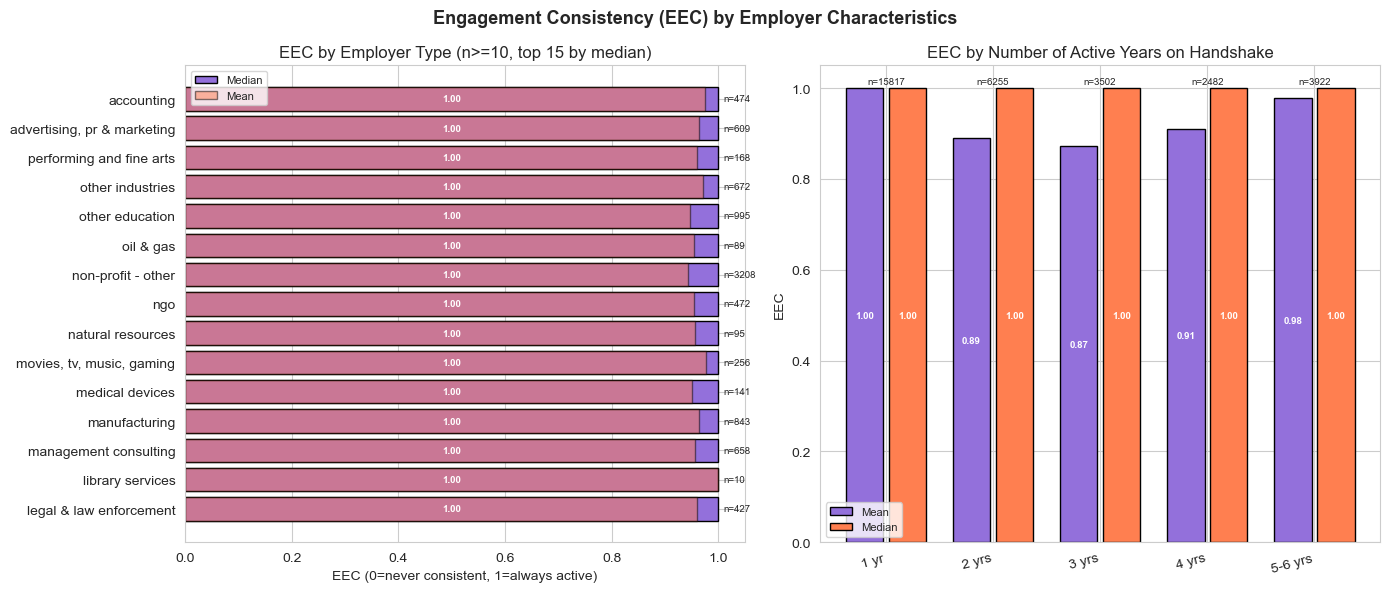

In [48]:
eec_data = employer_inf[employer_inf['EEC'].notna()].copy()

# Active years band (replaces size band — size data too sparse)
eec_data['active_years_band'] = pd.cut(
    eec_data['active_years_unified'].fillna(0),
    bins=[0, 1, 2, 3, 4, 7],
    labels=['1 yr', '2 yrs', '3 yrs', '4 yrs', '5-6 yrs'],
    include_lowest=True
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. EEC by employer type (horizontal)
type_eec = eec_data.dropna(subset=['employer_type'])\
    .groupby('employer_type')['EEC'].agg(['mean', 'median', 'count'])\
    .reset_index().query('count >= 10')\
    .sort_values('median', ascending=False).head(15)

bars_med  = axes[0].barh(type_eec['employer_type'][::-1], type_eec['median'][::-1],
                          color='mediumpurple', edgecolor='black', label='Median')
bars_mean = axes[0].barh(type_eec['employer_type'][::-1], type_eec['mean'][::-1],
                          color='coral', edgecolor='black', alpha=0.5, label='Mean')

for bar, val in zip(bars_med, type_eec['median'][::-1]):
    if bar.get_width() > 0.05:
        axes[0].text(bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                     f'{val:.2f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

for bar, (_, row) in zip(bars_med, type_eec[::-1].iterrows()):
    axes[0].text(max(row['mean'], row['median']) + 0.01,
                 bar.get_y() + bar.get_height()/2,
                 f"n={int(row['count'])}", va='center', fontsize=7)

axes[0].set_xlabel('EEC (0=never consistent, 1=always active)')
axes[0].set_title('EEC by Employer Type (n>=10, top 15 by median)')
axes[0].legend(fontsize=8)

# 2. EEC by active years band
years_eec = eec_data.dropna(subset=['active_years_band'])\
    .groupby('active_years_band', observed=True)['EEC']\
    .agg(['mean', 'median', 'count']).reset_index()
x = range(len(years_eec))

bars_mean2   = axes[1].bar([i-0.2 for i in x], years_eec['mean'], 0.35,
                            label='Mean', color='mediumpurple', edgecolor='black')
bars_median2 = axes[1].bar([i+0.2 for i in x], years_eec['median'], 0.35,
                            label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean2, years_eec['mean']):
    if bar.get_height() > 0.05:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.2f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_median2, years_eec['median']):
    if bar.get_height() > 0.05:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.2f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

axes[1].set_xticks(list(x))
axes[1].set_xticklabels(years_eec['active_years_band'], rotation=15, ha='right')
axes[1].set_ylabel('EEC')
axes[1].set_title('EEC by Number of Active Years on Handshake')
axes[1].legend(fontsize=8)
for i, (_, row) in enumerate(years_eec.iterrows()):
    axes[1].text(i, max(row['mean'], row['median']) + 0.01,
                 f"n={int(row['count'])}", ha='center', fontsize=7)

plt.suptitle('Engagement Consistency (EEC) by Employer Characteristics',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Event Type Analysis Segmented by Employer Characteristics
Which event types are most common and best attended across employer type and size.

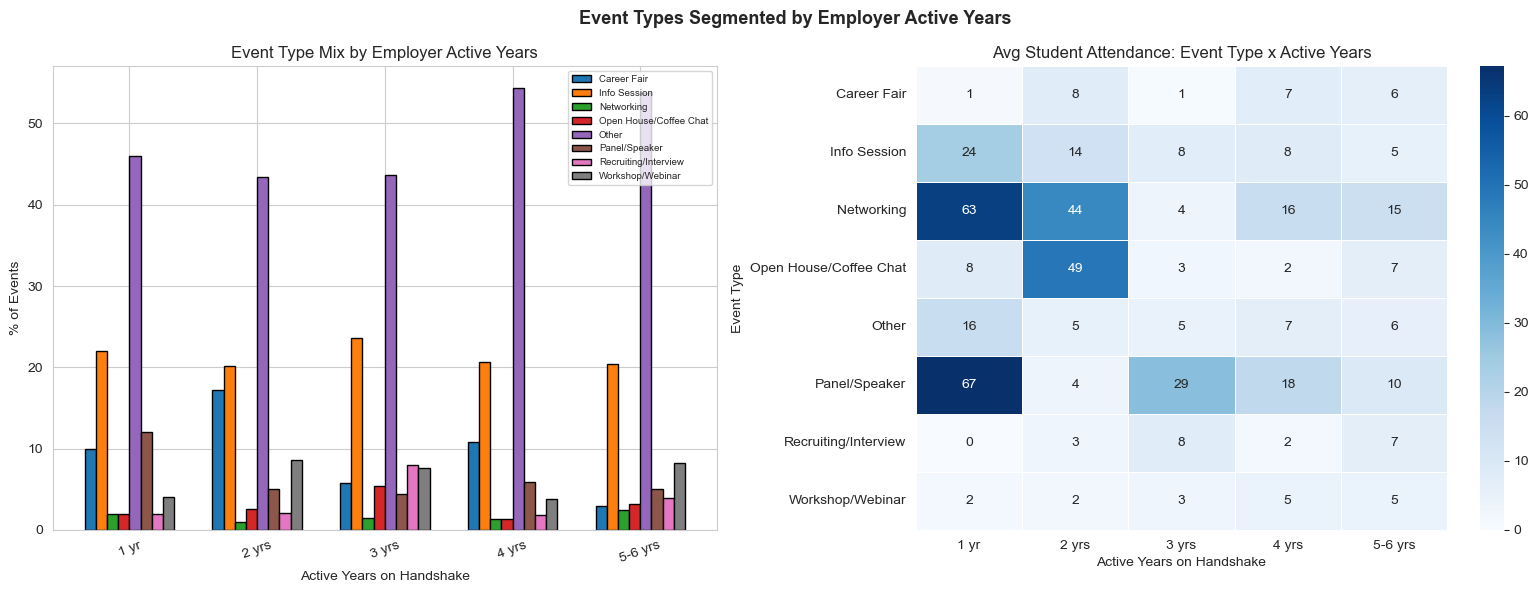

In [49]:
# Join event type back to employer characteristics
events_typed = ep_joined.dropna(subset=['events_id'])\
    .drop_duplicates(subset=['events_id']).copy()
events_typed['events_name_lower'] = events_typed['events_name'].str.lower().str.strip()

def categorize_event(name):
    if any(k in name for k in ['career fair','job fair','hiring fair']): return 'Career Fair'
    elif any(k in name for k in ['info session','information session','infosession']): return 'Info Session'
    elif any(k in name for k in ['networking','network']): return 'Networking'
    elif any(k in name for k in ['workshop','seminar','training','webinar']): return 'Workshop/Webinar'
    elif any(k in name for k in ['interview','recruiting','recruitment']): return 'Recruiting/Interview'
    elif any(k in name for k in ['panel','speaker','talk','presentation']): return 'Panel/Speaker'
    elif any(k in name for k in ['open house','office hour','coffee chat']): return 'Open House/Coffee Chat'
    else: return 'Other'

events_typed['event_type'] = events_typed['events_name_lower'].apply(categorize_event)

# Merge employer type and active years (replaces size band)
emp_attrs = employer_inf.reset_index()[['employer_id', 'employer_type', 'active_years_unified']]
events_typed = events_typed.merge(emp_attrs, on='employer_id', how='left')

events_typed['active_years_band'] = pd.cut(
    events_typed['active_years_unified'].fillna(0),
    bins=[0, 1, 2, 3, 4, 7],
    labels=['1 yr', '2 yrs', '3 yrs', '4 yrs', '5-6 yrs'],
    include_lowest=True
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Event type distribution by active years band
type_years = events_typed.dropna(subset=['active_years_band'])\
    .groupby(['active_years_band', 'event_type'], observed=True).size()\
    .unstack(fill_value=0)
type_years_pct = type_years.div(type_years.sum(axis=1), axis=0) * 100
type_years_pct.plot(kind='bar', ax=axes[0], edgecolor='black', width=0.7)
axes[0].set_xlabel('Active Years on Handshake')
axes[0].set_ylabel('% of Events')
axes[0].set_title('Event Type Mix by Employer Active Years')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(fontsize=7, loc='upper right')

# Avg attendance by event type and active years band
att_type_years = events_typed.dropna(subset=['active_years_band'])\
    .groupby(['event_type', 'active_years_band'], observed=True)['student_attendees_count'].mean()\
    .unstack(fill_value=0)
sns.heatmap(att_type_years, ax=axes[1], cmap='Blues', annot=True, fmt='.0f', linewidths=0.5)
axes[1].set_title('Avg Student Attendance: Event Type x Active Years')
axes[1].set_xlabel('Active Years on Handshake')
axes[1].set_ylabel('Event Type')

plt.suptitle('Event Types Segmented by Employer Active Years', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Year-over-Year Trends Segmented by Employer Type
Job posting and application trends broken out by top employer sectors.

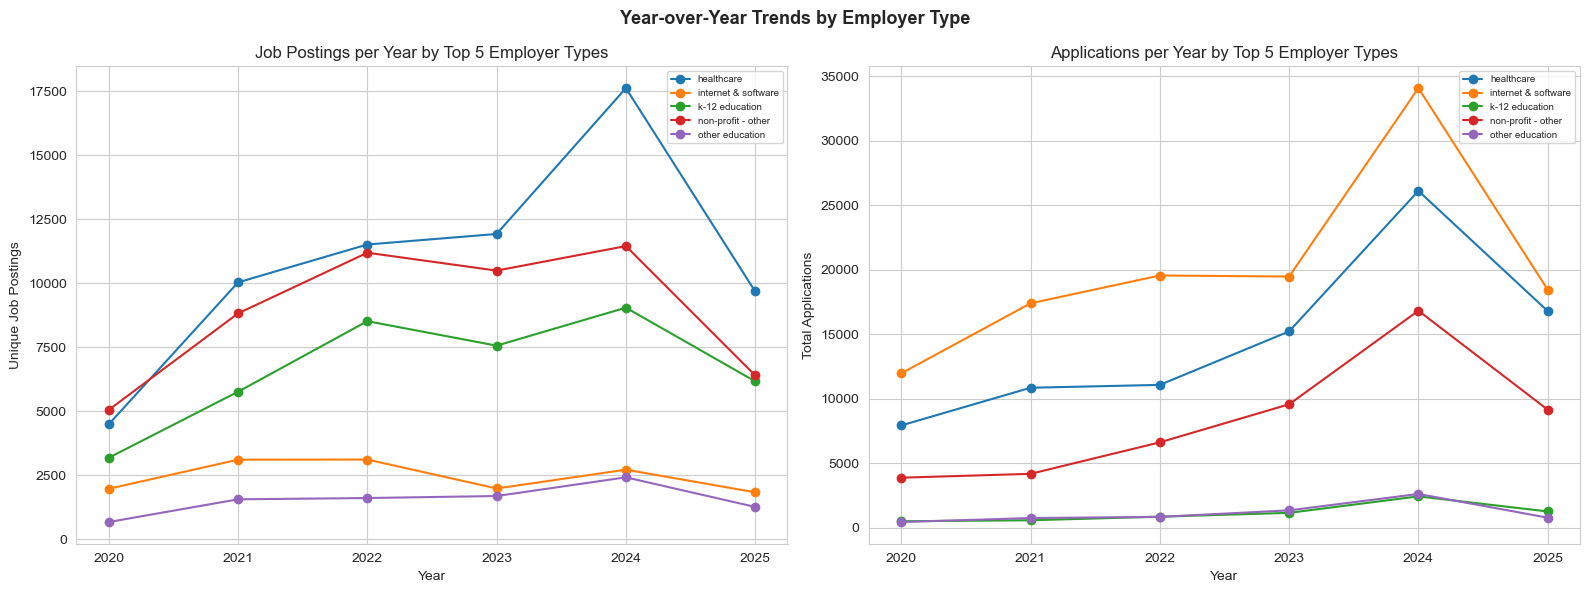

In [50]:
# YoY trends by employer type (top 5 sectors)
jobs_emp = ep_joined.dropna(subset=['jobs_id'])\
    .drop_duplicates(subset=['jobs_id']).copy()
jobs_emp['year'] = pd.to_datetime(jobs_emp['job_creation_date'], errors='coerce').dt.year

# Drop employer_type if already in ep_joined to avoid suffix conflict on merge
jobs_emp = jobs_emp.drop(columns=['employer_type'], errors='ignore')

jobs_emp = jobs_emp.merge(
    employer_inf[['employer_id', 'employer_type']], on='employer_id', how='left'
)

top5_types = employer_inf['employer_type'].value_counts().head(5).index
jobs_top = jobs_emp[jobs_emp['employer_type'].isin(top5_types)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Jobs per year by type
jobs_yr_type = jobs_top.groupby(['year', 'employer_type']).size().unstack(fill_value=0)
jobs_yr_type.plot(ax=axes[0], marker='o')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Unique Job Postings')
axes[0].set_title('Job Postings per Year by Top 5 Employer Types')
axes[0].legend(fontsize=7)

# Applications per year by type
apps_yr_type = jobs_top.groupby(['year', 'employer_type'])['applications_count'].sum().unstack(fill_value=0)
apps_yr_type.plot(ax=axes[1], marker='o')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Total Applications')
axes[1].set_title('Applications per Year by Top 5 Employer Types')
axes[1].legend(fontsize=7)

plt.suptitle('Year-over-Year Trends by Employer Type', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Student Engagement Segmented by Employer Characteristics
Attendance and application distributions broken out by event medium and employer size.

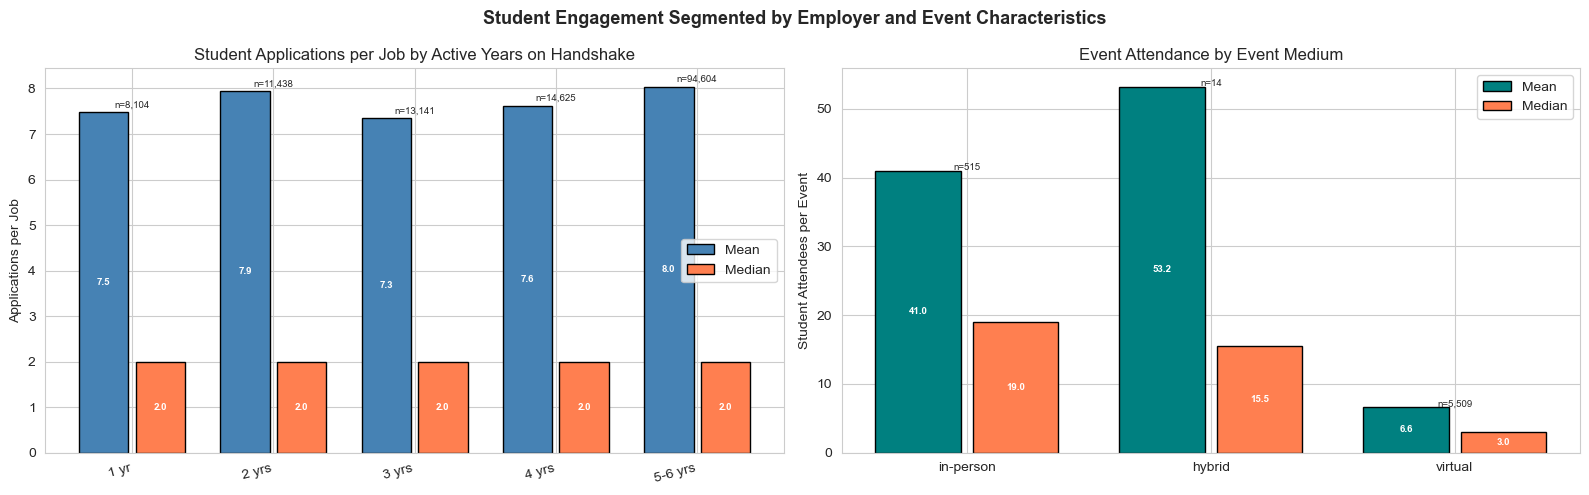

In [51]:
# Applications per job by active years band
jobs_seg = ep_joined.dropna(subset=['jobs_id'])\
    .drop_duplicates(subset=['jobs_id']).copy()

jobs_seg = jobs_seg.drop(columns=['employer_type', 'active_years_unified'], errors='ignore')
jobs_seg = jobs_seg.merge(
    employer_inf[['employer_id', 'employer_type', 'active_years_unified']],
    on='employer_id', how='left'
)

jobs_seg['active_years_band'] = pd.cut(
    jobs_seg['active_years_unified'].fillna(0),
    bins=[0, 1, 2, 3, 4, 7],
    labels=['1 yr', '2 yrs', '3 yrs', '4 yrs', '5-6 yrs'],
    include_lowest=True
)
jobs_seg = jobs_seg[jobs_seg['applications_count'] > 0]

# Attendance per event by medium
events_seg = ep_joined.dropna(subset=['events_id', 'event_medium'])\
    .drop_duplicates(subset=['events_id'])\
    [['event_medium', 'student_attendees_count']]\
    .query('student_attendees_count > 0')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Applications per job by active years band
years_apps = jobs_seg.groupby('active_years_band', observed=True)['applications_count']\
    .agg(['mean', 'median', 'count']).reset_index()
x = range(len(years_apps))

bars_mean = axes[0].bar([i-0.2 for i in x], years_apps['mean'], 0.35,
                         label='Mean', color='steelblue', edgecolor='black')
bars_med  = axes[0].bar([i+0.2 for i in x], years_apps['median'], 0.35,
                         label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean, years_apps['mean']):
    if bar.get_height() > 0.3:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_med, years_apps['median']):
    if bar.get_height() > 0.3:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

axes[0].set_xticks(list(x))
axes[0].set_xticklabels(years_apps['active_years_band'], rotation=15, ha='right')
axes[0].set_ylabel('Applications per Job')
axes[0].set_title('Student Applications per Job by Active Years on Handshake')
axes[0].legend()
for i, (_, row) in enumerate(years_apps.iterrows()):
    axes[0].text(i, max(row['mean'], row['median']) + 0.1,
                 f"n={int(row['count']):,}", ha='center', fontsize=7)

# Attendance per event by medium
med_att = events_seg.groupby('event_medium')['student_attendees_count']\
    .agg(['mean', 'median', 'count']).reset_index().sort_values('median', ascending=False)
x2 = range(len(med_att))

bars_mean2 = axes[1].bar([i-0.2 for i in x2], med_att['mean'], 0.35,
                          label='Mean', color='teal', edgecolor='black')
bars_med2  = axes[1].bar([i+0.2 for i in x2], med_att['median'], 0.35,
                          label='Median', color='coral', edgecolor='black')

for bar, val in zip(bars_mean2, med_att['mean']):
    if bar.get_height() > 0.3:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')
for bar, val in zip(bars_med2, med_att['median']):
    if bar.get_height() > 0.3:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                     f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')

axes[1].set_xticks(list(x2))
axes[1].set_xticklabels(med_att['event_medium'])
axes[1].set_ylabel('Student Attendees per Event')
axes[1].set_title('Event Attendance by Event Medium')
axes[1].legend()
for i, (_, row) in enumerate(med_att.iterrows()):
    axes[1].text(i, max(row['mean'], row['median']) + 0.1,
                 f"n={int(row['count']):,}", ha='center', fontsize=7)

plt.suptitle('Student Engagement Segmented by Employer and Event Characteristics',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [52]:
# Full employer KPI summary
kpi_cols = [
    'employer_id', 'employer_name', 'employer_type',
    'total_jobs', 'total_applications', 'JAY',
    'total_events_dedup', 'total_attendees_dedup', 'EAY',
    'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI',
    'EEIS_equal', 'EEIS_pca', 'EEIS_rank',
    'rank_equal', 'rank_pca', 'rank_based',
    'active_years_unified', 'years_span'
]
available = [c for c in kpi_cols if c in employer_inf.columns]
kpi_summary = employer_inf[available].copy()

# Drop employers with no name — they have zero jobs/events and no engagement data
# These exist in ep_base_cleaned but never appeared in ep_joined
before = len(kpi_summary)
kpi_summary = kpi_summary[kpi_summary['employer_name'].notna()].copy()
kpi_summary['employer_name'] = kpi_summary['employer_name'].astype(str).str.strip()
kpi_summary['employer_type'] = kpi_summary['employer_type'].fillna('Unknown').astype(str)
after = len(kpi_summary)

kpi_summary = kpi_summary.sort_values('EEIS_equal', ascending=False)

print(f'Total employers before filter: {before:,}')
print(f'Dropped (no name / no activity): {before - after:,}')
print(f'Total employers in KPI table: {after:,}')
display(kpi_summary.head(20))

# Export
kpi_summary.to_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'), index=False)
print(f"\nExported employer_kpi.csv")
print(f"Rows: {len(kpi_summary):,}")
print(f"Columns: {available}")

Total employers before filter: 56,089
Dropped (no name / no activity): 24,160
Total employers in KPI table: 31,929


,employer_id,employer_name,employer_type,total_jobs,total_applications,JAY,total_events_dedup,total_attendees_dedup,EAY,EEB,...,avg_salary_mid,SSI,EEIS_equal,EEIS_pca,EEIS_rank,rank_equal,rank_pca,rank_based,active_years_unified,years_span
135,9226,ey,accounting,383,2723.0,7.109661,314.0,2404.0,7.656051,2,...,79093.620339,5.623288e+05,0.564389,0.646164,99.899490,1.0,1.0,9.0,6.0,6.0
1731,18383,jpmorganchase,financial services,985,9732.0,9.880203,109.0,1366.0,12.532110,2,...,81271.011275,8.029741e+05,0.443114,0.491405,99.970805,2.0,3.0,1.0,6.0,6.0
2461,22003,amazon,internet & software,795,14015.0,17.628931,61.0,989.0,16.213115,2,...,58425.773099,1.029984e+06,0.434246,0.485572,99.954537,3.0,4.0,2.0,6.0,6.0
4947,39013,pwc,accounting,221,2615.0,11.832579,173.0,2261.0,13.069364,2,...,89280.434783,1.056418e+06,0.428640,0.498426,99.795637,4.0,2.0,25.0,6.0,6.0
759,13661,morgan stanley,investment banking,450,5346.0,11.880000,185.0,1386.0,7.491892,2,...,88620.940000,1.052817e+06,0.405373,0.458816,99.921776,5.0,7.0,4.0,6.0,6.0
921,14620,mckinsey & company,management consulting,178,4198.0,23.584270,165.0,1797.0,10.890909,2,...,151298.275517,3.568259e+06,0.400480,0.464081,99.751734,6.0,5.0,39.0,6.0,6.0
838,14072,goldman sachs,investment banking,164,6919.0,42.189024,129.0,1596.0,12.372093,2,...,91849.999000,3.875062e+06,0.398874,0.462715,99.720979,7.0,6.0,49.0,6.0,6.0
32,8530,kpmg llp,accounting,140,4326.0,30.900000,158.0,1535.0,9.715190,2,...,39260.000000,1.213134e+06,0.368375,0.426414,99.663481,8.0,8.0,61.0,6.0,6.0
728,13523,capital one,commercial banking & credit,27,549.0,20.333333,246.0,1164.0,4.731707,2,...,110000.000000,2.236667e+06,0.327816,0.376154,98.291332,9.0,9.0,687.0,6.0,6.0
46,8594,deloitte,management consulting,213,2654.0,12.460094,81.0,1890.0,23.333333,2,...,77641.800000,9.674241e+05,0.317176,0.371022,99.782043,10.0,10.0,29.0,6.0,6.0



Exported employer_kpi.csv
Rows: 31,929
Columns: ['employer_id', 'employer_name', 'employer_type', 'total_jobs', 'total_applications', 'JAY', 'total_events_dedup', 'total_attendees_dedup', 'EAY', 'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS_equal', 'EEIS_pca', 'EEIS_rank', 'rank_equal', 'rank_pca', 'rank_based', 'active_years_unified', 'years_span']


In [55]:
# Percent of employers posting jobs, hosting events, and doing both
total_employers = ep_joined['employer_id'].nunique()

emp_with_jobs = ep_joined.dropna(subset=['jobs_id'])\
    .groupby('employer_id')['jobs_id'].nunique()
emp_with_events = ep_joined.dropna(subset=['events_id'])\
    .groupby('employer_id')['events_id'].nunique()

n_jobs   = (emp_with_jobs > 0).sum()
n_events = (emp_with_events > 0).sum()
n_both   = len(set(emp_with_jobs[emp_with_jobs > 0].index) &
               set(emp_with_events[emp_with_events > 0].index))

pct_jobs   = n_jobs   / total_employers * 100
pct_events = n_events / total_employers * 100
pct_both   = n_both   / total_employers * 100

print(f"Total unique employers:               {total_employers:,}")
print(f"Employers posting jobs:               {n_jobs:,}  ({pct_jobs:.2f}%)")
print(f"Employers hosting events:             {n_events:,}  ({pct_events:.2f}%)")
print(f"Employers doing both jobs and events: {n_both:,}  ({pct_both:.2f}%)")
print(f"Employers with no activity:           {total_employers - n_jobs:,}  ({100-pct_jobs:.2f}%)")

Total unique employers:               56,089
Employers posting jobs:               31,929  (56.93%)
Employers hosting events:             935  (1.67%)
Employers doing both jobs and events: 886  (1.58%)
Employers with no activity:           24,160  (43.07%)
